# Statistical Modelling and Inferencing
## Graded Assignment — Auto MPG: Fuel Efficiency Analysis

**Course Code:** MDS DF401
  
**Name:** Riddhi Bhatt  

**BITS ID:** 2026EM1100040

**Submission Date:** 25-11-2026

#Executive Summary
This study investigates the factors associated with automobile fuel efficiency using the Auto MPG dataset, comprising 398 observations from 1970 to 1982. Exploratory data analysis, descriptive statistics, correlation analysis and data quality assessment were conducted to identify significant patterns and prepare the dataset for statistical modelling. Following the removal of six observations with missing values, 392 observations were retained for analysis.

Five regression models were developed and systematically evaluated using statistical significance testing, multicollinearity assessment, regression assumption testing and five-fold cross-validation. The final log-transformed multiple linear regression model incorporates vehicle weight, model year and geographical origin. Logarithmic transformation substantially improved residual diagnostics, while HC3 robust standard errors strengthened statistical inference. The selected model achieved a cross-validation R-squared of 0.8525 and an independent test R-squared of 0.8485, with an MAE of 2.0126 MPG and RMSE of 2.7811 MPG.

The findings indicate that lower vehicle weight, newer model years and geographical origin are significantly associated with improved historical fuel efficiency. Practical recommendations are provided for automobile manufacturers, consumers and data analysts. The study also acknowledges limitations related to historical data, omitted variables, residual assumptions and generalisability, while demonstrating the importance of systematic statistical modelling and uncertainty estimation in data-driven decision-making.

# Part 1: Data Exploration and Preparation

## 1.1 Introduction and Objective

The objective of this analysis is to investigate the relationship between automobile characteristics and fuel efficiency, measured in miles per gallon (MPG).

The study aims to develop, compare and validate regression models, assess statistical significance, examine model assumptions and identify the key predictors associated with fuel efficiency.

## 1.2 Importing Libraries and Loading the Dataset

The Auto MPG dataset is loaded using the Seaborn library, as specified in the assignment. The initial inspection helps establish the dataset structure, dimensions and variable types.

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import base64
import gzip
import io

sns.set_theme(style="whitegrid", palette="Set2")

EMBEDDED_DATA = "H4sIAOPJBmsC/5Vc25bbuI5991fobbrXODm8X97mT2apbMWljmx5JLtSla8fEuBdcubMQ3fSqwWRBIGNjU3K1/vlePqaxtt5WNbjeVzvU38arsPtcXyfl3W4z7+G5fhrGC/vj2N/Og3TsPSPcb4dr/N5mP77a+iX47yMl/F2vPXX4UDNd3I0R060+5Ny4v7NJRFHytzfNDk+1/54eh8+lnkaHp3/2zBNQ3ftp/HteaASraW3o8r/F1eWHyn9LqP123M8/ezWn19Tv/zsOCNpTPiTgi0XXHmrNOZ9+rrOz8d7t/YPN+L4cFNVYaqiNOPVVPvrqVuGt2Hq1vVxoDpY+CeoQAthj5Tk6f2Yl3P3cC65zXE5gln/vPXTE1xQ/zypnr/0U/85Dp0kbjUCjaT/kzECRlIc7Z4Dx+vdmSYbmBKDYQWn7GjyvJIDfjyXr24cxzyQhIHASDBZze4+3x5jf+pO/cPt0K1PO2Rhh+Df3EhSjuR91l/f+nXtz/PSne9TsjLcW2mMCsWroc7z+TK4iOhdPNwuw9KtQ5wiFxgPYKeIPZqdjf2P0/Pcd+7R5HZC8sZqRZ0H5daDV7dCN2y/TPOeRzgxqpomht+wPlwcdb/6y3zr/lp//X1g3tbFOfVLtPACrtkR5uJM/+nv/e34mL/mR9+d5mW+9S7oXQC7jWA+nFQIEDQ1Pg7lzu6dn+tjWDDkvYmPCuvDkmktKhO/DS6Hb8PjwCg8zcAhBgaQRh8hAcowvPYfw+KWd2AaFgMvNgZiivuIx7fjWs79Y33euvskKTkwlQ2E/zs1XLoB0WB4LvN9OH7M08/VuWy4dc5NtHMA8vwc3D6f+9sB48/5D+YIK1Lef7p6xX14Xob54RJFJI8D1EAkMlHMMlj0z/PYUUK6aU1jQMbHPZLtGGvfv3XWDnFRFNyHG8sYBywrn3+7/uqca1l0c9gUmJASJoVA3JTLMlxdLh1wpT6gc9IqKo8QheW2/GCSpKdhtbiTwkV19XYf1V/dyUMiLSCRUXzaOHfyHCCYcGf3roMtkdD6hQrN3dNFVr87L7pHz3+MDbobGwbdCEmMbnF+CbFKm3T8GC59x7ibUwqInFCMmeAdupdQ0QTyyPlI+L3Ap5Mv7+Pt4RLdYkJwAHKCW+V3lufHq61S+DwMQInEUmGrNWwrTHdyyTpfsWw4a6xqMBrnzL7wwKYm2sIaHM5dAaqMi5qDJcRslseZMZWNX97VobqD6ASzRdkVzMEsVkL655qDKKuxfPh9pYVPmvLRvS3z8/LeX/OQkFsSQo5KEQKU/rE0loVeEKuqbdupc6wsPgasrJTVRDEXXC3oTzPiObwzLw+stI8o1kTUaX7eHm6o9X+e4zLsGnvfSBf/lXH0zdr/6Jcx2IWNk7BASFtmFau8knG9W+/z8ujf3HJDDWJFpmkGiEhMlQRNpuGodhufzMTaVc/2h1vj27ic81RzWFKfEaLZv6vLgf52OTAewBR2Q2E6k5TO/vnrsJz8pp36u3OIA5uMHZCAiB2U8WQVENj9M3WOjJADEE5x1EiWACl9WbQ4qaaIOLyLBrAADbMiSqZVBIMfY/9w6CfeDpzi+wHpAQy05snBG0yaph5Q88ARmWBPFLBBRfkRfNiCJjxfgizUB1dPRRpnW0+BjbuqSlMlptED1Mc6VuImQ06+1nt6sKUuTEe0YLvU5b1fzo/5nhDXV1ATtkcdAfCcZUHr5umRjXheXGC5LvMZx+G2i3t83YeOH5AKV3UkRLeMg9XRjQW5jTnleU+yyEWhW543yKWYvTUc6tjDsH8fDh0zroxesukS0KgjTpTnGb4k7jV2+nrC81Bb7NTbbgcIFs1DNcwdWh5atDCMQDoqzkNvxaq8dXzWYeDa+A/ItJCEVatCGj0Na/+25ELJKseDO4RUleE8ndfr/Da6AulC3kWkMd0yf/XT0KCuRXPGAl+L+7Z8ra6J7W7DL4+eaIsQyDFhkE5zT2p4mQHX/rdrMJZP5iH/PqTNKz1qbD1cUWWrylD2x66ERVrDXnGB03xzgy5r85Lch7oNEoHQlwGw9LdIDNByr4JqXQ3/ksgUNSqzYqgylvOAmWX+fswdFXKoaxOYIdJKSgME7mW9oDRYxizOnYHVNuX9tjMIZgEIVYRcRo1tx1uGW/+cPLg3s8yIwa3cOhYRA01MRjML3gCqFSCwgnbHhoMNL5aE8SaJSi7MiPvcdIv1oKB8IO4ipd7DXbTY0nZCEhTuVy5FSB1wsgA3MAfE4UVGn4bbw2MBl5mu7UMO39LQahQBLNt6XxajFI17oMeizAUOqySCBV/y3VzYw12ufRqwbBQd6JzvM7FCqErRsbJeUgOHBeflG10CGTPbWx+woJObweTweDxl7yDqo5jkNZTCO7DQ6XHezXPX61ZeqQsLuAdb8TjPUk3SXAbM5xsc7b7m5af7a14o2ypLVtLqBUFHmYbTY3EdH5PJxbxoizHWXOdaGzeFKg9stn0a9bZqZ9kfLoD62yM1dxX99fzH7G3Lbf7o01S3fZaD4QgXvJVhdigzaSbXyDB8IwxZIqrXt8LQVoix0m8iWmxRdnWVzDlwGB6+gNJtgFobqwN/QXxYaaRgYEtUlUtlo9RuMIyipKgCOXNUrDzr8+25vDUEAVs5N8NqrIIgfIyrh7PFZWHWzKrd0sYG1OSbpj/wzQIxGZYdeLpGTNfB3TLfrPovGioV32Wood4AsbICFSmbQqKqHoqGzj7ylMC3Y9PME0/5BJ7CkdWkaoZ6FyVB1uGtKBLlK4nJA1VJaFbtft2ifagUb6bQdmRoHXjbP2HD2tCnAu0dnWev0D7LtN0apXuMOYYsyqds4ejItT2uuRUu4+eBoTsUojZEkNJpd+q5mtwVQbZJhELTLg1az6uDkT71J+Av6L9cH5/d1+iR05q3p2BSRm2GiExKDLsNA+c+AQpwDLpev6SqFZcSBkK5S5F2akH4dEAAS/GhAAjCcGZEN4EWgj/K2FFzLJKTKxSEyE5yzldIANJCnItQFhJA7ENcqWa7eaGCS+LjNYTuKX2W0IChYgPRckeq46oaoK4FSRKAgXREXIQJUWfwG8tSeUhKbGMlrVZcJCVnreBg3HQQz8UfBIeoniIUoeQv2It1ABTtlUFt6AuTRqXMLEVtFCxHUlgopmLL+XYqNkgjewGQG5J1eHOIe8lneEUnRP0Jm2gComJ/dX+KBchG7UrssNnp+flcX3dQQsbUEC+pY21dzldxU4Xjnzu3gkwL5seVedxNtxkQD9sEPL+gNvm2RKQf82eMzDKSFU8DbLnDuV/fG8qhDQIySc7c4mRMGG8mwQ9K5Ent6fohCWAFiuL5B99PMZ0PHGwOfcpktbu5OYrYWD5MTLvoXBTUpigwoVK4tfXuccrYm1s9kUhHnPz7fHMl+zR+uAyKQyAl4NiC0jQjNHB8qF+eW+zxomkKpnI2n/S7TWAIyYZgCycxuJhddtxS3YAOeAIibWXbAGOFpcCGuHBIgNgl61bJ7fJyet8zgZoLJVruwbvaqvTKl1CaLV6qbiXzECKWw3Yt/vC/H5cENVXio3IjN95D1uEbq0atE6igJcCQTd8Wjop4rtTcusJbOq2Cpha2sV3ynN3k1+NihunFhYsGrjWP5Uv+Ga4xgrQXOe1OBMHqY7EuF0R4jH9Z3+h473/9REZgHEFh2YL5Nom3Cwq88LdrH/+TNaIYIB+nKh5iyc2JBJy82wK6MPk1TTG9V12TdAPYjZiq/Hp0M0rg1GSHftA65aqeo3w7gqm0rNrMGM79+ljmBC8cSCcIVjpJrfKPp6QwBEVRPBZc+QeYj3w4XzmQQqaFb1A4XlGAIfB5a0SVLqWjbDEp1G+5Thm5ndTSv72Nj5re4W0URmm1G9699/7kVxCcS1PwMmVFCsUtQa9kOmwBrc9cXRlUdxJKldOaJAiI1rmO0TMhzlMiaoGb46x0DvcNN+c8H/BIvE9j4x0Gua0n3enjdErnaNDVoa4p0hm8qusWp/nsHTCPpsM69d0Wj+djt4ptoggqsXOE5yFloWP0OVd0jFC4HJjA/HV8tKzOOsybZgaDh9+8mEhWcR/TATzhcUAW4jiVoa9U/x8e257MWFK9paZ5WYSSYQLA1BhiOB7iJm80p++yEPZYmjD7buLzGw4b7gxF3oyRj5eGRDTaKF3RqKwVXEbpXu0Vccj6dHWIAnxT6CNUNbesWXkpps5IYmRlUN5MwrQHbQJWzoi/N8S+sxdb9XgMfk4yRpBK4rczolujX/N8/nqNLqyIoo9fEVVephi4doeyke1mKEl3grpf7150G2o+BUDPpaNs4XSk3vPeDXR5H/sDlIG0f6G5Qr0x+SuWhw/gB323/oMZEYt86LH9pUqd4yuBZHf+1+TdJVNZhKg0DOKxctcGjCNNl9nLPmM0LqnuhL+xgqgX5VfCago/t+VXwdRKiU0qSO46HovyK8I5GyWBUPosw41p8FgmElHqK1ZA2rNtWs1Tvwzd3dXu0Xnuw2RFJyu8rhz7XS1xsywYoYAFpYVgxeAkIfO+0qJgQykoWQFhDOJzuSzProfzsH57G26/O2bIipaNgMoNXEzJydOfR+fqkwvTD/eXYe9cRhAZj7ZVefXM1/2Kh+ENYKNJKLPFFv1wy911uJbxElyZOmfq71HQIvXBWcTHP9AjXWVmfzqB6OyrH4/KHM3HZTiG8WaZg0JFG9fn72e4nHjgRU+MJBlSwfhw0239kd3lARVdJoEHKRk0xBInWYVQvyzzr+6yesiRTe5gYpu8sJA7P75R0r33j9P7W+9boLreYQOAW5rG+8Opkg5sO0OKICo2ALoV7U7Phzf0xwYu6odU63D7MDQo5ouO5tXdqrJKtmEimJWBM+habXY2fXnMo7c4KDH+xc6Sw9n5AS7BpF4k9LBMBlqjt7fL64Y5AjsnAdj1LhzkhjnP0SLAM1n5tQT4ppPFzATORX1m6headjf9k/ZAFj0wVXBct+ONUkif3Gv6Z3xBdW+CJ8DX9Xmfz6r5Lc03trUAfJxHqlss8PH+9F8XwKWxqt8yGOUkmbwqLIWMDYkFQyId1yLKHbWHXJ74AcNRQ6VQyXRIYXB5uyLqNP54QHrFbMZ+D/gq4JPM2NF0ldCNclIAFfBWImNfol8RmwAChVxHNAxl61yCU/3rv64R2PCaGCp2RqY0KKWizrUacU5ZqANGKzDAXjd+4Xo6HCdiI2do3ugKm4yv6jTgX3naQEjgs7q8Ns0ZGfF5jrgcHtcsXr7RzeWbb+IguJtwIHPCxEXDW7T5v4KoO4/DOkwe12naH7ywjqKl8C/JNWr0N/09szG+CpgkWVpUPeDpcoaX6ZRKh//fJaS73SShdJjtwUB3+UyzovnaH4mwZl71dm4atoFwztMhnHkJ4f003wpM9bPNSB6UIBmYjykL8XifZte8eDxlBYRbJLFxo82ewhd4rHWGDRBLDg5NY8VMvr/Pww2BLuI34FTgsTLmsdm/HgJzrD99sCqmb7nR/bh4aOz+6p+P+W+f9jSnvUlBKdsASXbX/vZ3mmJZMAQWjLyyumCg51sNozbx9BzKmMdQ4gKocR5QuGJJ9emF6zlOYz95S1P7gkNEAmust+v3cH//ArlP5eWEhoNBEOs6KKCx8c/TLCciMRUU5kZ31gLNBmx6w1+gKvPdbd0pX74YJ4fgR2NCwAtE7ZBluPRTeQjd/eUc9Db/jRNvQtkhtq+hrN7vp++qEukqskUQE3lP6Zhrf7k9r53HA5KFD+SuoduR22XmXlcjmPL8yYrEk1uWIaHR93zg1EJdOJDRG+Dx32e4eVnQWGQuj+mLjnIp8/UGaE3bCdHIpdsJDdN4cpj4KMopx8mFfkdiEZdVEBbnfXe3V7M3Mrnw4wdSMmoKG4BzgL34a+rd+uktbeMLQSLJbHzh8uKbNyHf+dFHD+YXx8+xSCjDppIJJYk3a303BkoBfjUWOLCqK5JvMpW4TN6JqhX9QGKQ6IVa9LtM8LEiy4OAQBEzyxQWsbVURKxT7JaMTX28xYJv9yvlehqX2fVNSQAoQpXDHqm2DoU2a/rEMp6VfjxdEjJApq1AfRocWq7+/ojbGNPisyUB0+0OJnXKExLeYLNBoYFHmxqbRSoDJcYmCmi3uDT5YcgW/LgiwQ12o+qofMdaFq2vIJUL/tiKqfYAQ7OIY7Y6KErYp0rtkEObAd+28K3/sGtIl7QNwi4iGMe2EcOc1atbH989co6gHtj2YjdXMaLsH7+PTF0K9gsMRQQ4D6h3bfd7GqwRDDkuppgiMmgKdrf0R7+mW8syXzqrhJ3iDaHHmQZHmWevtf66df+VZgQv4hQQpcwpFuUKu5ESY+vCBaAmKO94jcMiswdfl/e2SgLp0aC85EstIq2oNyh8XBEEgdQtaaCfiDEoeqgkw+SQX+/j4uaJJxHCAx90HlojKfOs1ddu24pKHYhKHL4IrPQh3B1LSBBMbS0qDdN5XvrznMqUoNGT3LcjDAqJ3T1c4QXRxSQWjAS12P6bPJcLHJZkWs4IqRIm1Z/3eRl/zzdvIxsbUBGLsG9tuseJ+1gxsQOAXWeEkcBybVN8fCHWgGvI/m3xZaUuHAJnNOtj8aJw3GmDOw2pZfNOq7zT9Ufz03gdH8PZGxo4ouO5DEkLrIfv4NX4gE//fTu9MdPY4NmdjYCLXsUG8KKLx9lK/MaDtWUicP+DKFQ//HSACoGOMWRHvjeYbDZ1UVbBdV7jH99t9x8+qiff56WuMOwzC8qdIS+7dgzknNuM4CUbkYcLu8yLz2Gr3TLIA7eDFD4Xbc3DbpJGq6rmebGE18Nwf2kGstmQTVfhgpLmg32sdYYi0TdkQ/Q5vr2UEvD7UlPsCFAkAZ/xWSRwSBqxxac0OXbvC7PEGDnFhbDNTbbCFptvxdSB6/KYGu/g8nDI226HrIRUzgIymFom8iD9Im4OQgGRK/aeYutm27k5XPeQZ1vym2SHystw+ClICx/wclvOp4APEfYk6SKMoC6ymyWdK4yohfztFRVRW3olj/HWEgWhbMcVVgy85IFH/Hj30bZh4JnyWljGb/lUtOQM76mXAdQcYAhXa9wiVcJIYAP+1ycoL3O7VEgcThPne+9LG32JP04AdDGPFTX8aXDNZarA2Hhkfc0Bj8S7jGm0rK+FKEfcARJnkP+W43zM21MznQ9zOH5PRQnKt5t9NuTbb2hrdLwGHm6V+EoIkn8Td8vnNw0HDLK8doo3S0jozPPsHsv4vN7fu8eio3bKsVUReNvWYvfEK9CJ2udpfltALBPprgEe0bF4DtjsEXYPiQrAHA3cghc2nNKZ5qPVZQhn2Zh5oScUeA8naJ/BptbymQxNpErAoFjMvfIr8H5xQVr9tAfH47ZQ74JCCfq4iqY7kB1jvFhV+CDUvlwVt1CAiuMmLcMBhWm+L/ZtrhvvwMMROmQSXDmAG9GFH/LHFK7+3n0kQHnMIqPGrobmMaoU8r/GwFkG/HDTUEk8Qk5G8VKizsfABde1OKEWtrrr/eJNdJU5jMjQ0LXLjpVaFEqpKZRvki2yIiv88zpROBWuwgYhoHVTpHBgJVIfLNNxo+/FTfGN+7CevKQkfnkIsLWBl+Zc6dJ7Buw9XjUI1FIUojwMse3R/3Gco8+MFLOSs6AEZJN0J8aMfhCdMxIrG82hX2753UXi8zzkJM7FkEuCB5Jm/0t3b5PFlvirGlEb2my9qwefvrirXNxzFpty53NxZyaosqmn4QxbFFEsPfcMcu1A4EuqP0GsFTIySU7xsFPV3v5IJtAVJXiGAGMWya7aemIZXMt5hmszLJ2Z4OrwWJ/vuML4LOg/xyt8DyTa65KCyrS52/ufgIOp+UI5WMeDxmCx0xVNayON4+doCrKOVsGarqBMKFFElogKslBBGEpA2DTR0H/lH3LI5QcaePD85rPn3t9Y8kdPemslwhnKSyuE7gMXG1v4lBeK90tb9u08z0u8WB2MkXTqmPn1x/z/+DvX3ToUTDIcc5bIL1lEJ7YpNeuQFlo0BZrXk22bongfs7hzZ1QEfrajggXpOl5qhKH8Zdzw6xCG7chg8f5DgU8OaEkgNez1adsUy0BGaNf8BsXNsA1Ch9O5KXq+BHZNUOp9aXbgppglonu48q+T+1p0v8JHgby8jUiSocbllfLZ9HX77LJDijuhVAW1PE3wNq6r/5zWsaLffZevkVQITGRjVXGiGL4kz4yJSAXYCwA2he/CBxxBJGsGwXtr4cLW9nm9+3w8G9sZxubcaBtef67J8Jo5NcWRcLjfkoK1+eImSBQ83JNTLJ9Z0XDr2LBX6HZyqdznbiN+UlFQP2my93dh6zqc+2mC1puVd7jDZ3q8jq4KKKfoWCryrWyFt9R2Ni8ekqQgKQmjDhJlBRuOxy3+F/Jcw7qHHDZxpy3MXftlTjYoJuClceTbqlpQ5PW+fxLFb7awqE0xgRa5Rby7TXzekwOKpTAUllS9lMUxUocbqT4gEbDIzmWF9DAl5+LLUOAzVDmWjmdtjie8kbZ+c53x/wJFxFmm5lIAAA=="

df = pd.read_csv(
    io.BytesIO(
        gzip.decompress(
            base64.b64decode(EMBEDDED_DATA)
        )
    )
)

print("Dataset dimensions:", df.shape)
print("\nFirst five observations:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset dimensions: (398, 9)

First five observations:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


## 1.3 Descriptive Statistics

Descriptive statistics provide an initial understanding of the central tendency, variability and range of the numerical variables.

Measures such as mean, median, standard deviation, quartiles and skewness help identify distribution characteristics, potential outliers and differences in variable scales.

Categorical variables are also examined to understand the composition of the dataset.

In [2]:
# Numerical descriptive statistics
summary = df.describe().T

summary["median"] = df.select_dtypes(include=np.number).median()
summary["variance"] = df.select_dtypes(include=np.number).var()
summary["skewness"] = df.select_dtypes(include=np.number).skew()

print("Numerical Descriptive Statistics:")
display(summary.round(2))

# Categorical descriptive statistics
print("\nCategorical Descriptive Statistics:")
display(df.describe(include="object").T)

# Frequency distributions
for col in ["origin", "cylinders", "model_year"]:
    print(f"\nFrequency Distribution: {col}")
    display(df[col].value_counts().sort_index().to_frame("Count"))

Numerical Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
mpg,398.0,23.51,7.82,9.0,17.50,23.0,29.00,46.6,23.0,61.09,0.46
cylinders,398.0,5.45,1.70,3.0,4.00,4.0,8.00,8.0,4.0,2.89,0.53
displacement,398.0,193.43,104.27,68.0,104.25,148.5,262.00,455.0,148.5,10872.20,0.72
horsepower,392.0,104.47,38.49,46.0,75.00,93.5,126.00,230.0,93.5,1481.57,1.09
weight,398.0,2970.42,846.84,1613.0,2223.75,2803.5,3608.00,5140.0,2803.5,717140.99,0.53
acceleration,398.0,15.57,2.76,8.0,13.82,15.5,17.18,24.8,15.5,7.60,0.28
model_year,398.0,76.01,3.70,70.0,73.00,76.0,79.00,82.0,76.0,13.67,0.01



Categorical Descriptive Statistics:


,count,unique,top,freq
origin,398,3,usa,249
name,398,305,ford pinto,6



Frequency Distribution: origin


,Count
origin,
europe,70
japan,79
usa,249



Frequency Distribution: cylinders


,Count
cylinders,
3,4
4,204
5,3
6,84
8,103



Frequency Distribution: model_year


,Count
model_year,
70,29
71,28
72,28
73,40
74,27
75,30
76,34
77,28
78,36


### Key Observations from Descriptive Statistics

- The average fuel efficiency is 23.51 MPG, with a standard deviation of 7.82 MPG and a range of 9 to 46.6 MPG, indicating considerable variability.
- Horsepower exhibits the highest positive skewness (1.09), indicating a longer right tail.
- Displacement and weight are also positively skewed, while acceleration is approximately symmetric.
- Horsepower contains six missing observations, accounting for approximately 1.51% of the dataset.
- USA-manufactured vehicles constitute 62.56% of the observations, indicating an imbalance in geographical representation.
- Four-cylinder vehicles are the most common, accounting for 204 observations.
- The dataset covers model years from 1970 to 1982.
- The vehicle name variable contains 305 unique values, indicating high cardinality. Its suitability as a predictor will be assessed during data preparation.

## 1.4 Univariate Distribution Analysis

Histograms and density curves are used to examine the distributions of continuous numerical variables, including their symmetry, skewness and spread.

Frequency plots are used for discrete and categorical variables to understand the composition of the dataset.

This analysis provides a foundation for identifying potential data quality issues and making informed preprocessing decisions.

In [3]:
BURGUNDY = "#30121E"
PANEL = "#3D1C29"
ROSE = "#C98B9B"
IVORY = "#F5E9E7"
MAUVE = "#A67C91"
PINK = "#E8BBC6"

sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "figure.facecolor": BURGUNDY,
    "axes.facecolor": PANEL,
    "axes.edgecolor": MAUVE,
    "axes.labelcolor": IVORY,
    "axes.titlecolor": IVORY,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.color": IVORY,
    "ytick.color": IVORY,
    "text.color": IVORY,
    "grid.color": MAUVE,
    "grid.alpha": 0.15,
    "grid.linestyle": "--",
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.facecolor": PANEL,
    "legend.edgecolor": MAUVE,
    "legend.labelcolor": IVORY
})

sns.set_palette([ROSE, PINK, MAUVE])

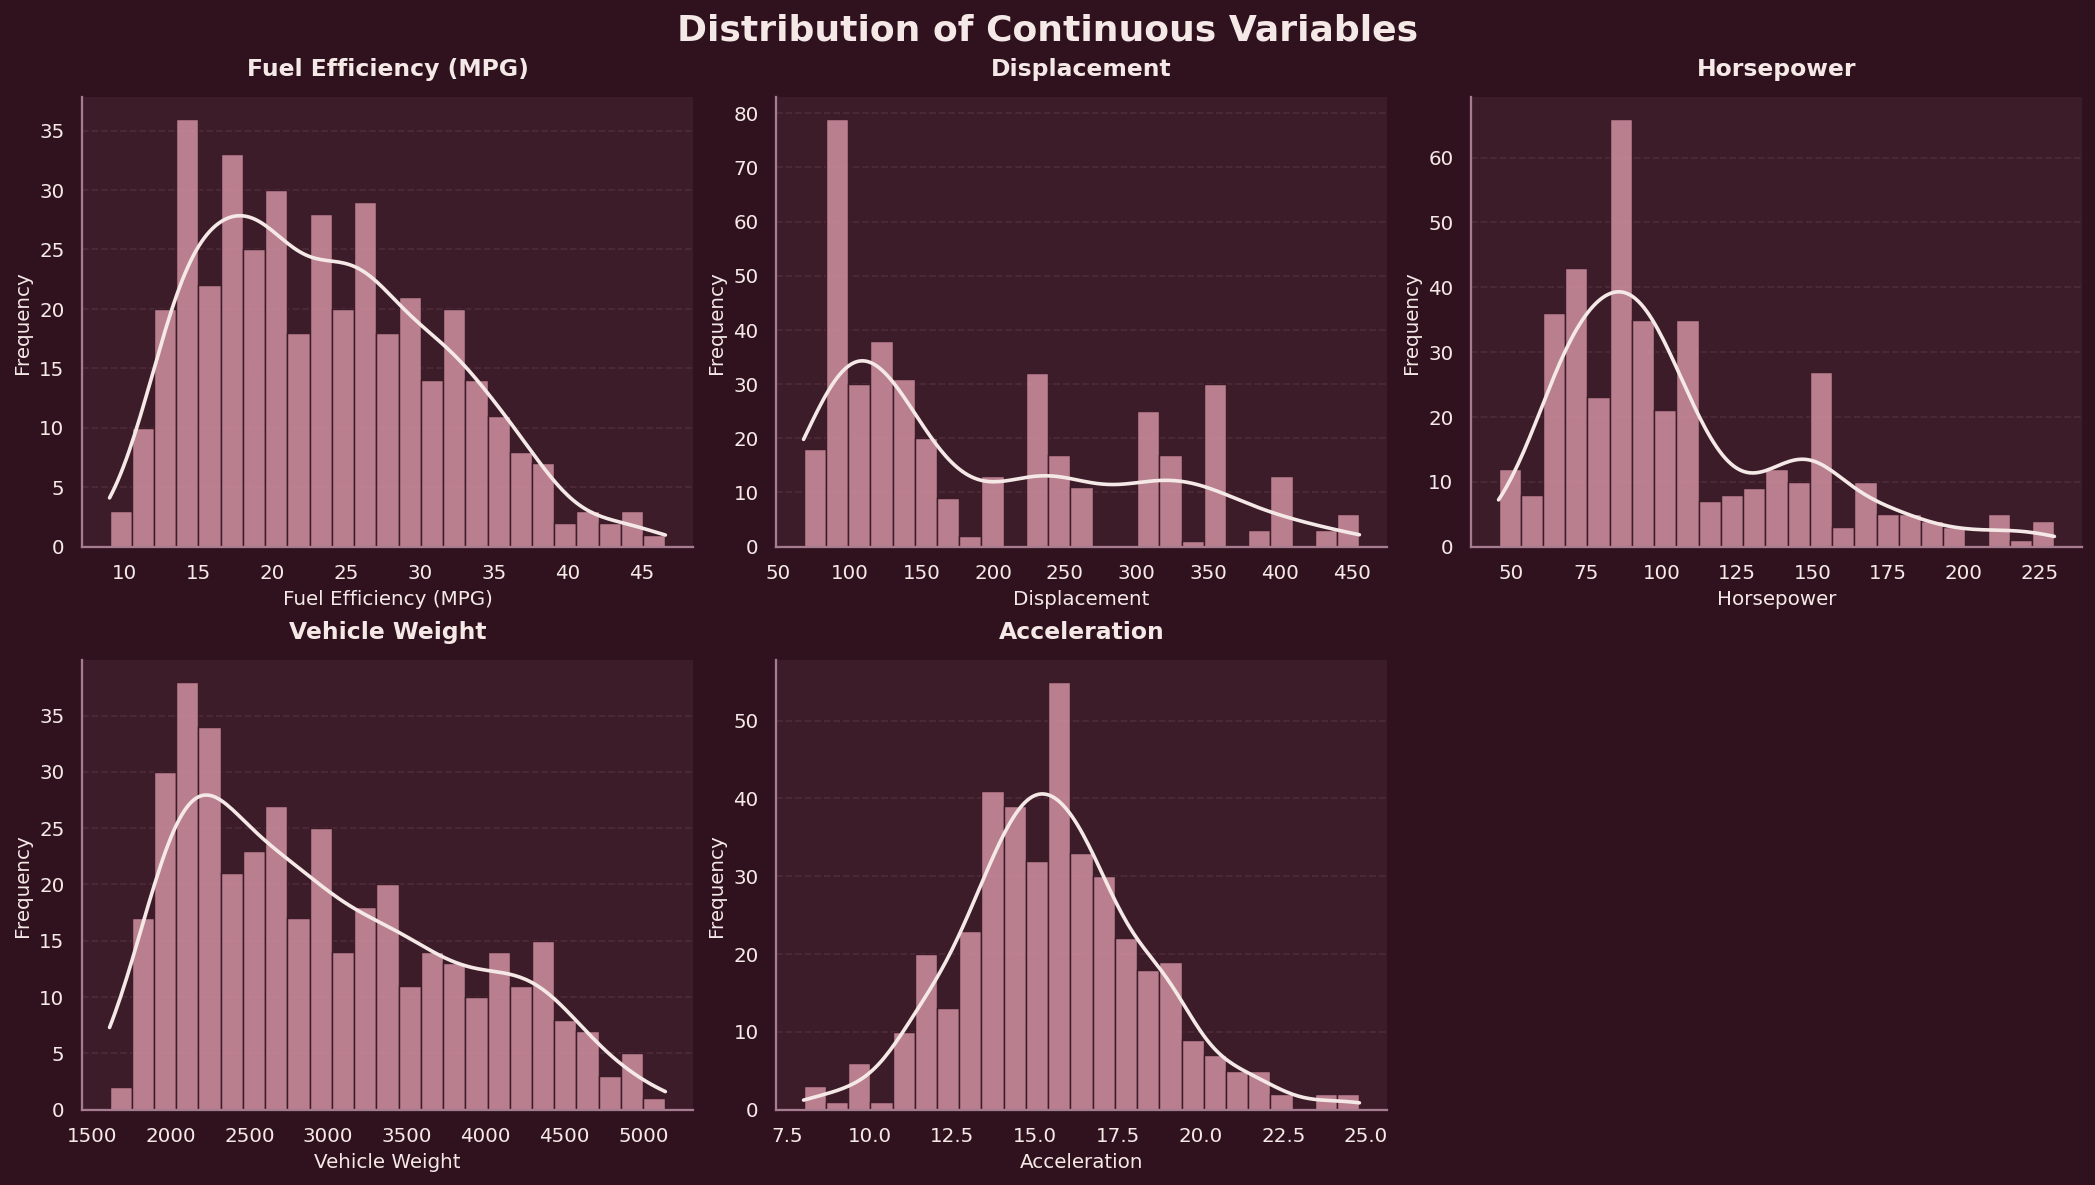

In [4]:
continuous_cols = [
    "mpg", "displacement", "horsepower",
    "weight", "acceleration"
]

labels = {
    "mpg": "Fuel Efficiency (MPG)",
    "displacement": "Displacement",
    "horsepower": "Horsepower",
    "weight": "Vehicle Weight",
    "acceleration": "Acceleration"
}

fig, axes = plt.subplots(
    2, 3, figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for ax, col in zip(axes, continuous_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=25,
        color=ROSE,
        edgecolor=PANEL,
        linewidth=0.8,
        alpha=0.9,
        ax=ax
    )

    for line in ax.lines:
        line.set_color(IVORY)
        line.set_linewidth(2)

    ax.set_title(labels[col], pad=12)
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Frequency")
    ax.grid(axis="x", visible=False)

fig.delaxes(axes[-1])

fig.suptitle(
    "Distribution of Continuous Variables",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

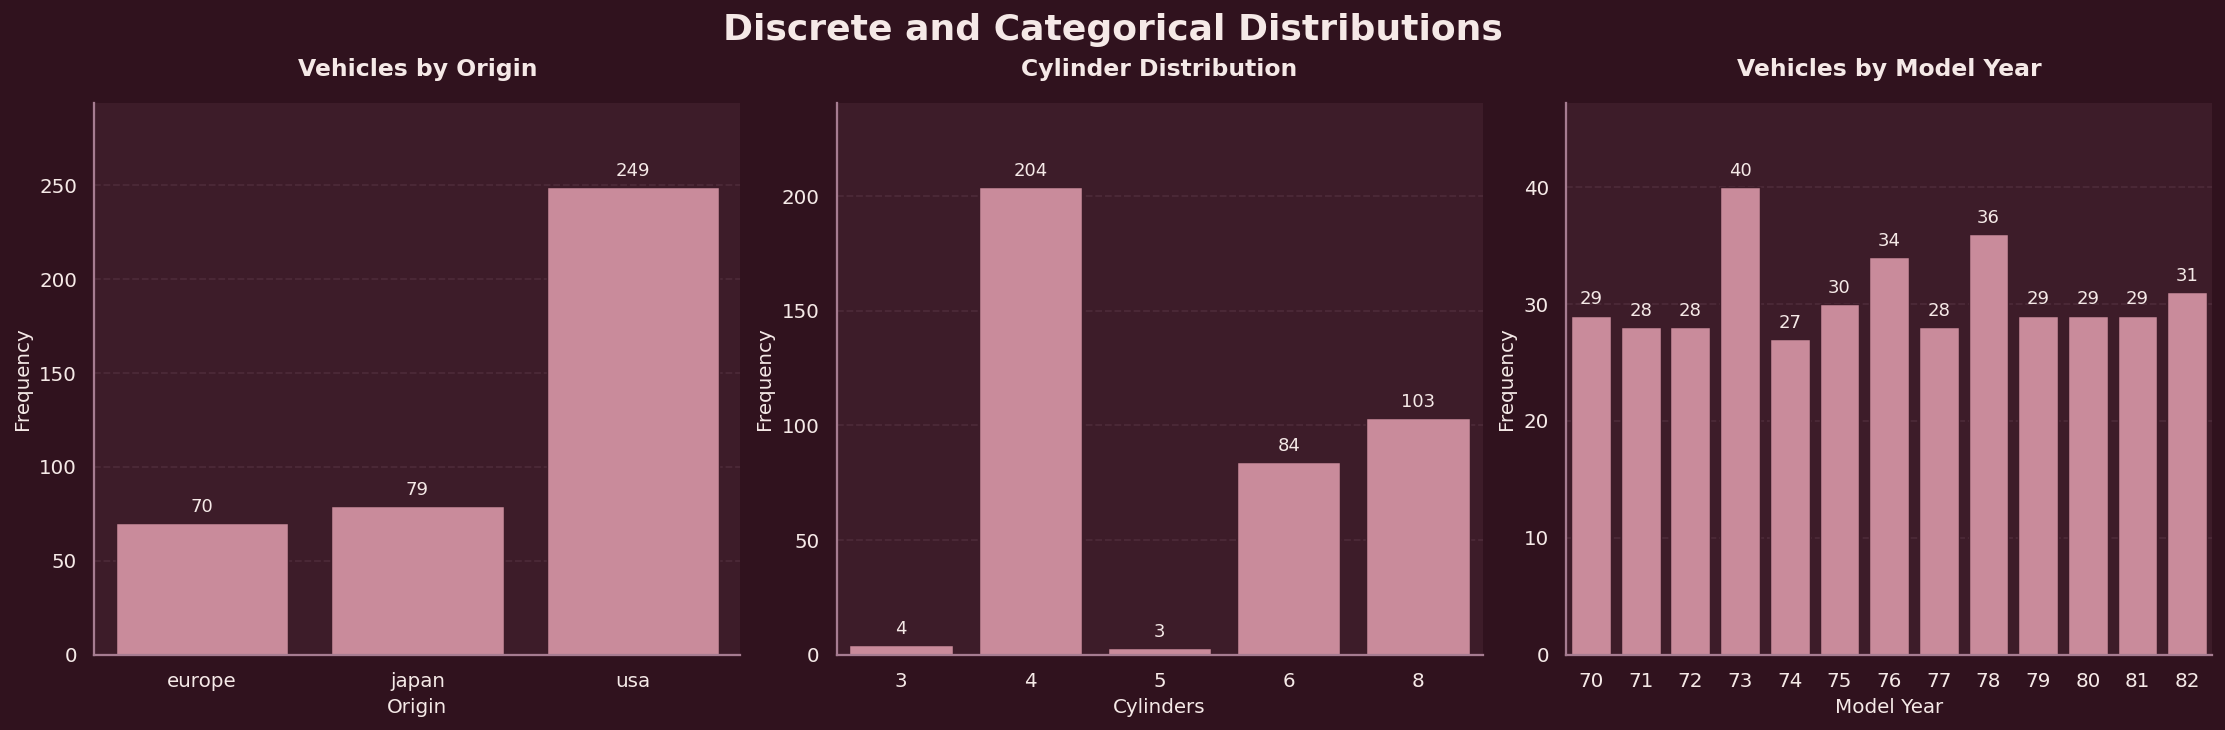

In [5]:
fig, axes = plt.subplots(
    1, 3, figsize=(17, 5.5),
    constrained_layout=True
)

columns = ["origin", "cylinders", "model_year"]

titles = [
    "Vehicles by Origin",
    "Cylinder Distribution",
    "Vehicles by Model Year"
]

for ax, col, title in zip(axes, columns, titles):

    sns.countplot(
        data=df,
        x=col,
        order=sorted(df[col].unique()),
        color=ROSE,
        saturation=1,
        edgecolor=PANEL,
        linewidth=0.8,
        ax=ax
    )

    ax.set_title(title, pad=15)
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Frequency")

    ax.bar_label(
        ax.containers[0],
        padding=4,
        fontsize=10,
        color=IVORY
    )

    ax.margins(y=0.18)
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Discrete and Categorical Distributions",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

## 1.5 Bivariate Relationship Analysis

Bivariate analysis examines the relationship between individual predictors and the target variable, MPG.

- Scatter plots with regression lines are used to examine the direction, strength and potential linearity of numerical relationships.
- Box plots are used to compare fuel efficiency across categorical and discrete groups.

These visualisations help identify potentially important predictors and guide subsequent regression model development.

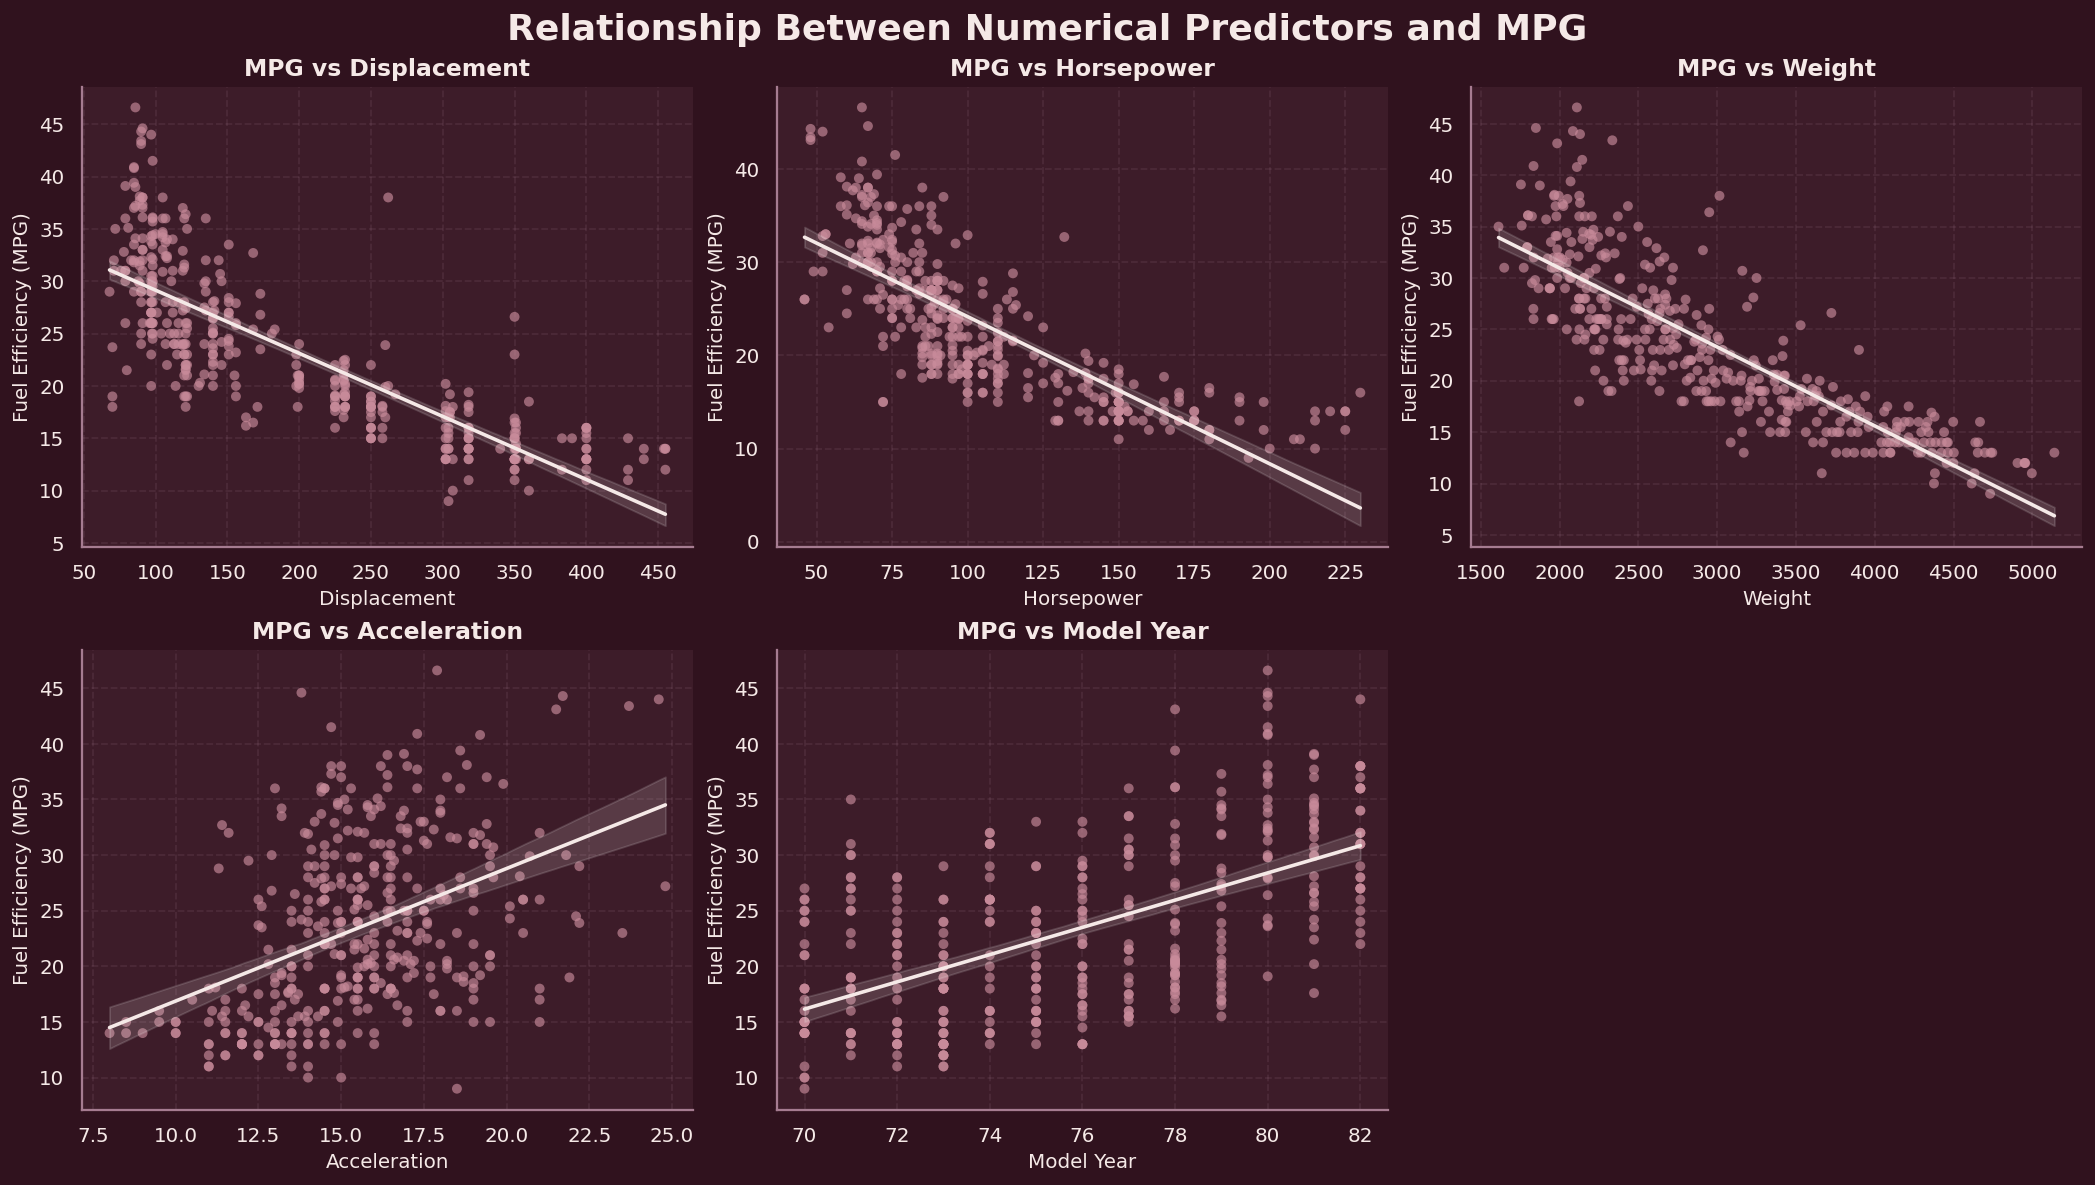

In [6]:
predictors = [
    "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]

fig, axes = plt.subplots(
    2, 3, figsize=(16, 9),
    constrained_layout=True
)

axes = axes.flatten()

for ax, col in zip(axes, predictors):

    sns.regplot(
        data=df,
        x=col,
        y="mpg",
        ax=ax,
        scatter_kws={
            "color": ROSE,
            "alpha": 0.65,
            "s": 30,
            "edgecolor": "none"
        },
        line_kws={
            "color": IVORY,
            "linewidth": 2
        },
        ci=95
    )

    ax.set_title(f"MPG vs {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    ax.set_ylabel("Fuel Efficiency (MPG)")

fig.delaxes(axes[-1])

fig.suptitle(
    "Relationship Between Numerical Predictors and MPG",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

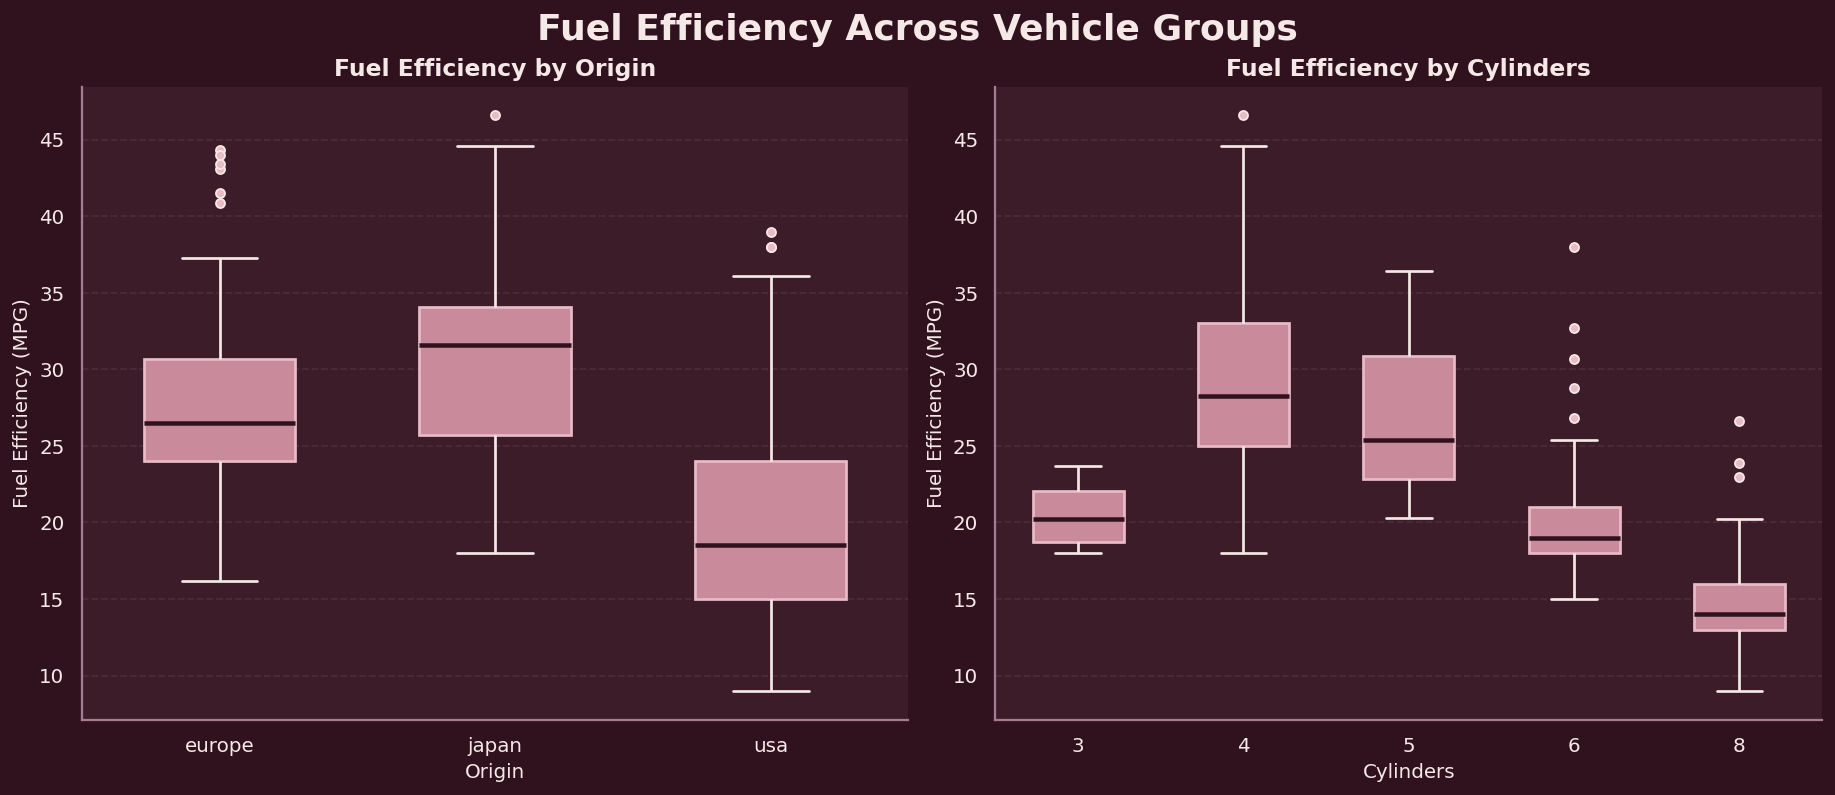

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 6),
    constrained_layout=True
)

for ax, col in zip(axes, ["origin", "cylinders"]):

    sns.boxplot(
        data=df,
        x=col,
        y="mpg",
        order=sorted(df[col].unique()),
        color=ROSE,
        saturation=1,
        width=0.55,
        linewidth=1.5,
        boxprops={"edgecolor": PINK},
        medianprops={"color": BURGUNDY, "linewidth": 2.5},
        whiskerprops={"color": IVORY},
        capprops={"color": IVORY},
        flierprops={
            "marker": "o",
            "markerfacecolor": PINK,
            "markeredgecolor": IVORY,
            "markersize": 5
        },
        ax=ax
    )

    ax.set_title(f"Fuel Efficiency by {col.title()}")
    ax.set_xlabel(col.title())
    ax.set_ylabel("Fuel Efficiency (MPG)")
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Fuel Efficiency Across Vehicle Groups",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

### Key Observations from Univariate and Bivariate Analysis

- Horsepower and displacement exhibit positive skewness, indicating a greater concentration of vehicles with smaller engines and lower horsepower.
- Weight, displacement and horsepower exhibit strong negative relationships with MPG.
- Weight appears to be one of the strongest individual predictors of fuel efficiency.
- Acceleration time exhibits a positive relationship with MPG, although the observations are more dispersed.
- Newer vehicle models generally exhibit higher fuel efficiency.
- Japanese vehicles have the highest median MPG, followed by European and American vehicles.
- Four-cylinder vehicles exhibit the highest median fuel efficiency, whereas eight-cylinder vehicles exhibit the lowest.
- Three-cylinder and five-cylinder groups contain very few observations, limiting reliable comparisons.
- Several potential outliers are visible in the box plots. These will be investigated before making removal decisions.
- Some relationships exhibit possible curvature, which will be examined during regression diagnostics.

These observations represent preliminary associations rather than causal relationships.

## 1.6 Correlation Analysis

Pearson's correlation coefficient is used to measure the strength and direction of linear relationships between numerical variables.

A correlation heatmap is constructed to identify:

- Predictors strongly associated with MPG.
- Relationships between independent variables.
- Potential multicollinearity among predictors.

Correlation analysis provides preliminary guidance for predictor selection. Multicollinearity will be investigated further using the Variance Inflation Factor (VIF) during model development.

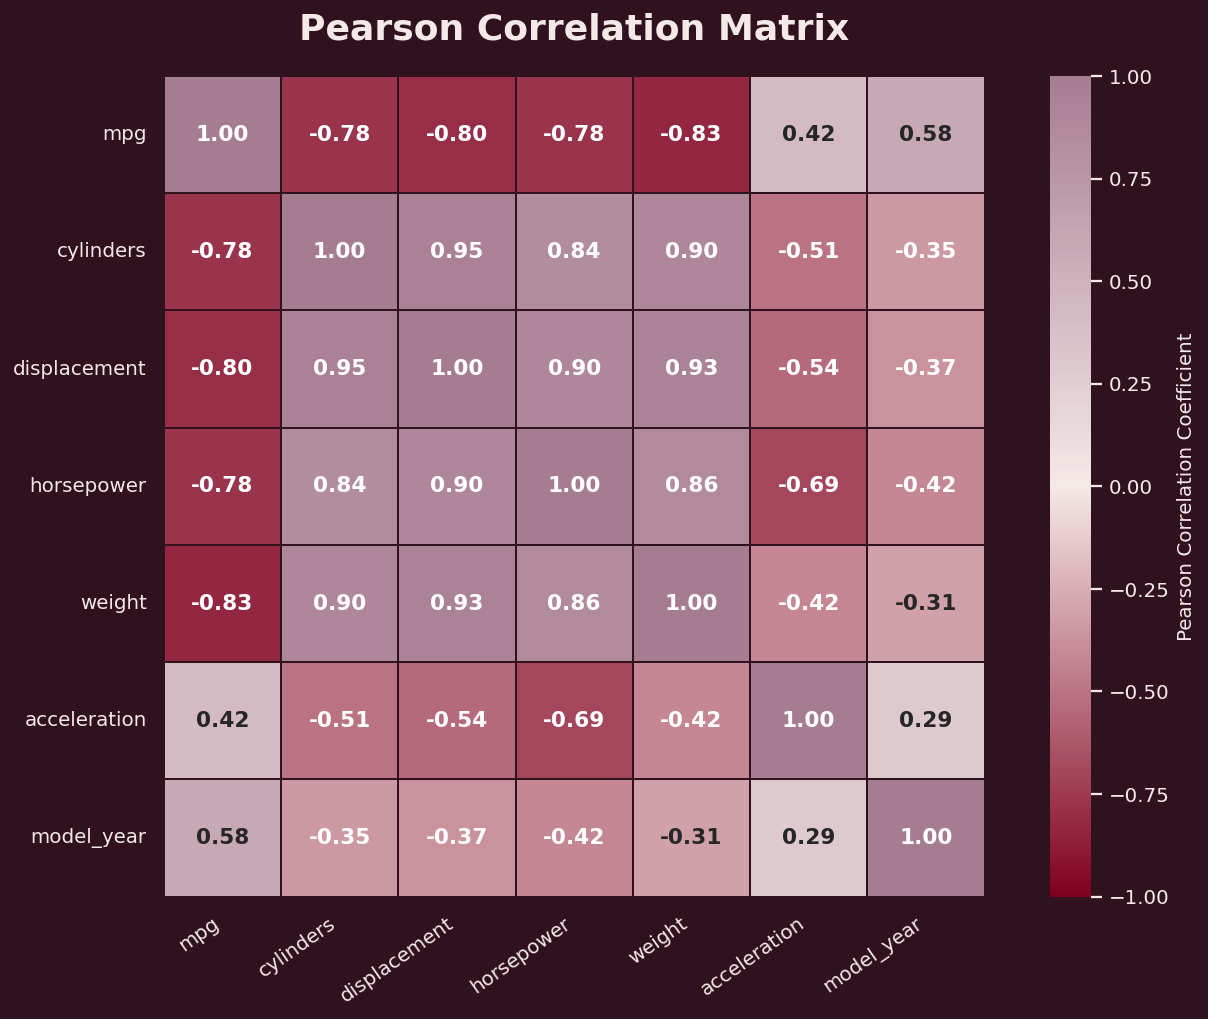

Correlation with Fuel Efficiency (MPG):


,Pearson Correlation
weight,-0.8317
displacement,-0.8042
horsepower,-0.7784
cylinders,-0.7754
model_year,0.5793
acceleration,0.4203


In [8]:
from matplotlib.colors import LinearSegmentedColormap

numeric_df = df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr(method="pearson")

custom_cmap = LinearSegmentedColormap.from_list(
    "burgundy_rose",
    ["#800020", "#F5E9E7", "#A67C91"]
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap=custom_cmap,
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=1,
    linecolor=BURGUNDY,
    annot_kws={"fontsize": 12, "fontweight": "bold"},
    cbar_kws={"label": "Pearson Correlation Coefficient"}
)

plt.title(
    "Pearson Correlation Matrix",
    fontsize=20,
    pad=20
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Correlation with target variable
target_corr = corr_matrix["mpg"].drop("mpg")

print("Correlation with Fuel Efficiency (MPG):")
display(
    target_corr.sort_values(
        key=lambda x: x.abs(),
        ascending=False
    ).to_frame("Pearson Correlation").round(4)
)

## 1.7 Data Quality Assessment

Data quality assessment is essential for ensuring reliable statistical inference and regression modelling.

The dataset is examined for:

- Missing values
- Duplicate observations
- Potential outliers using the Interquartile Range (IQR) method

Observations below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

Flagged observations will not be automatically removed, as they may represent genuine automobile characteristics rather than measurement errors.

In [9]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": df.isnull().mean() * 100
})

print("Missing Value Assessment:")
display(missing_summary.round(2))

print("Duplicate observations:", df.duplicated().sum())

Missing Value Assessment:


,Missing Values,Missing Percentage (%)
mpg,0,0.00
cylinders,0,0.00
displacement,0,0.00
horsepower,6,1.51
weight,0,0.00
acceleration,0,0.00
model_year,0,0.00
origin,0,0.00
name,0,0.00


Duplicate observations: 0


In [10]:
outlier_results = []

for col in continuous_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Variable": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Potential Outliers": count,
        "Outlier Percentage (%)": count / df[col].count() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage (%)
0,mpg,17.50,29.00,11.50,0.25,46.25,1,0.25
1,displacement,104.25,262.00,157.75,-132.38,498.62,0,0.00
2,horsepower,75.00,126.00,51.00,-1.50,202.50,10,2.55
3,weight,2223.75,3608.00,1384.25,147.38,5684.38,0,0.00
4,acceleration,13.82,17.18,3.35,8.80,22.20,7,1.76


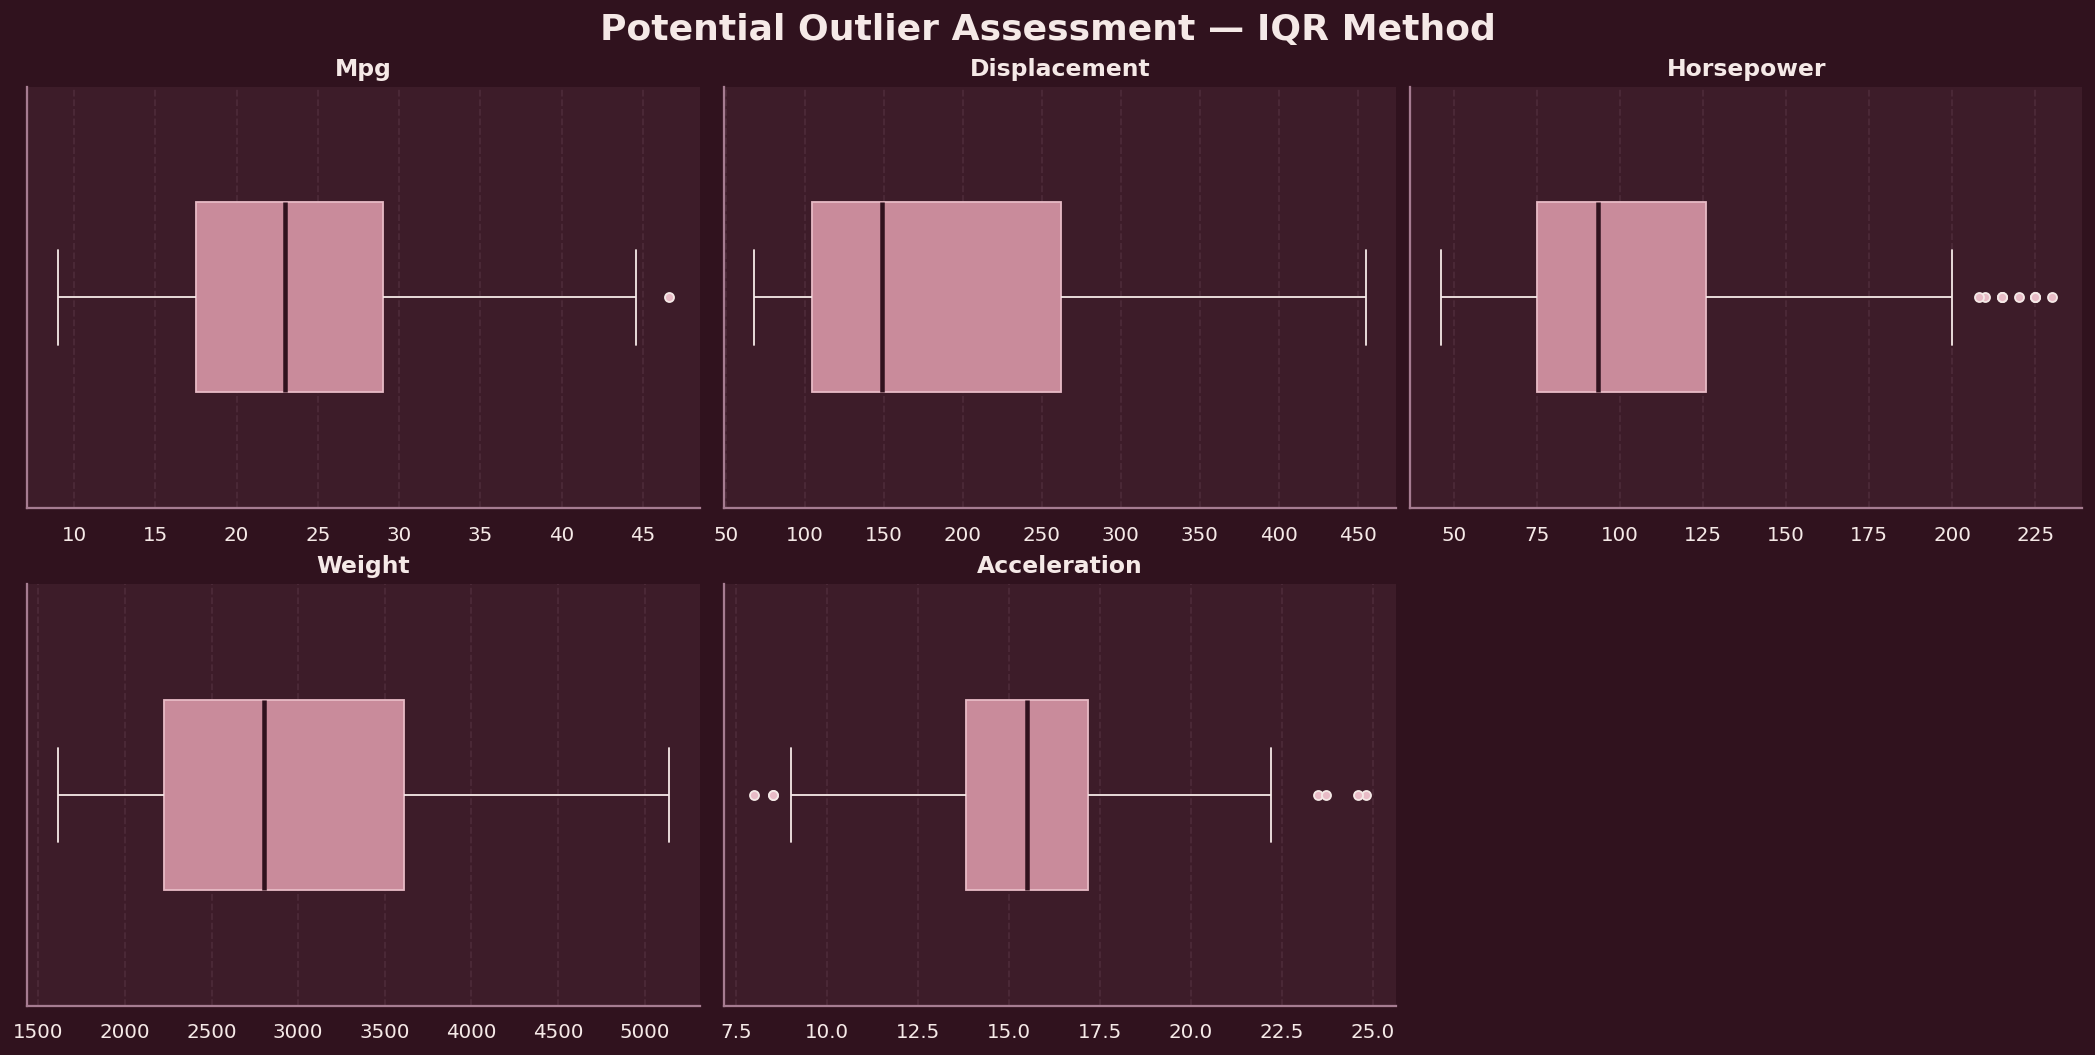

In [11]:
fig, axes = plt.subplots(
    2, 3, figsize=(16, 8),
    constrained_layout=True
)

axes = axes.flatten()

for ax, col in zip(axes, continuous_cols):

    sns.boxplot(
        data=df,
        x=col,
        color=ROSE,
        saturation=1,
        width=0.45,
        boxprops={"edgecolor": PINK},
        medianprops={"color": BURGUNDY, "linewidth": 2.5},
        whiskerprops={"color": IVORY},
        capprops={"color": IVORY},
        flierprops={
            "marker": "o",
            "markerfacecolor": PINK,
            "markeredgecolor": IVORY,
            "markersize": 5
        },
        ax=ax
    )

    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("")
    ax.grid(axis="y", visible=False)

fig.delaxes(axes[-1])

fig.suptitle(
    "Potential Outlier Assessment — IQR Method",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

### Correlation and Data Quality Findings

- Weight exhibits the strongest negative correlation with MPG (-0.8317), followed by displacement (-0.8042), horsepower (-0.7784) and cylinders (-0.7754).
- Model year exhibits a moderate positive correlation (0.5793), suggesting that newer vehicles tend to have better fuel efficiency.
- Acceleration exhibits a positive correlation (0.4203).
- The relationships among engine-related predictors warrant further investigation for multicollinearity using VIF.
- Horsepower contains six missing values, representing 1.51% of the dataset.
- No duplicate observations are present.
- The IQR method identifies one potential outlier in MPG, ten in horsepower and seven in acceleration.
- Potential outliers will be retained initially because extreme values may represent genuine vehicle characteristics. Their influence will be assessed during regression diagnostics.

## 1.8 Data Cleaning and Preprocessing

The following preprocessing decisions are adopted:

1. Missing Values:
   Complete-case analysis is selected because only 1.51% of observations contain missing values. Removing these observations avoids introducing artificial horsepower values through imputation. This assumes that the missing observations do not introduce substantial selection bias.

2. Duplicate Observations:
   No duplicate removal is required.

3. Outlier Treatment:
   Potential outliers are retained because there is no established evidence of measurement errors. Their influence will be evaluated during model diagnostics.

4. Vehicle Name:
   The name variable is excluded from modelling because it has high cardinality and functions primarily as a vehicle identifier.

5. Categorical Encoding:
   Origin is encoded using dummy variables, with USA as the reference category. One category is omitted to avoid perfect multicollinearity.

6. Numerical Variables:
   Numerical predictors are retained in their original units to facilitate practical interpretation of regression coefficients. Cylinders is initially treated as a numerical count variable.

In [12]:
# Preserve the original dataset
df_clean = df.copy()

# Remove observations with missing horsepower
df_clean = df_clean.dropna(subset=["horsepower"])

# Remove high-cardinality identifier
df_clean = df_clean.drop(columns=["name"])

# Encode origin with USA as the reference category
df_clean["origin"] = pd.Categorical(
    df_clean["origin"],
    categories=["usa", "europe", "japan"]
)

df_clean = pd.get_dummies(
    df_clean,
    columns=["origin"],
    drop_first=True,
    dtype=int
)

df_clean = df_clean.reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Processed dataset shape:", df_clean.shape)
print("Observations removed:", len(df) - len(df_clean))
print("Data retained (%):", round(len(df_clean) / len(df) * 100, 2))
print("Remaining missing values:", df_clean.isnull().sum().sum())

print("\nProcessed Dataset:")
display(df_clean.head())

print("\nFinal Variable Types:")
display(df_clean.dtypes.to_frame("Data Type"))

Original dataset shape: (398, 9)
Processed dataset shape: (392, 9)
Observations removed: 6
Data retained (%): 98.49
Remaining missing values: 0

Processed Dataset:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan
0,18.0,8,307.0,130.0,3504,12.0,70,0,0
1,15.0,8,350.0,165.0,3693,11.5,70,0,0
2,18.0,8,318.0,150.0,3436,11.0,70,0,0
3,16.0,8,304.0,150.0,3433,12.0,70,0,0
4,17.0,8,302.0,140.0,3449,10.5,70,0,0



Final Variable Types:


,Data Type
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,int64
acceleration,float64
model_year,int64
origin_europe,int64
origin_japan,int64


### Data Preparation Summary

The final processed dataset contains 392 observations and nine variables, comprising eight predictors and one dependent variable.

A total of 98.49% of the original observations have been retained. No missing values remain, and all variables are numerical and suitable for regression modelling.

The original dataset has been preserved for reproducibility and reference.

# Part 2: Model Development and Validation

## 2.1 Defining Variables and Splitting the Dataset

Fuel efficiency (MPG) is the dependent variable, while the remaining eight variables are candidate independent variables.

The dataset is divided into:

- Training set (80%): Used for model estimation, statistical inference, diagnostics and model selection.
- Testing set (20%): Reserved for evaluating the predictive performance of the final selected model on unseen observations.

A fixed random state of 42 ensures reproducibility.

A significance level of 0.05 and a confidence level of 95% are adopted throughout the regression analysis.

In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["mpg"])
y = df_clean["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

alpha = 0.05

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Observations": [len(X_train), len(X_test)],
    "Percentage (%)": [
        len(X_train) / len(X) * 100,
        len(X_test) / len(X) * 100
    ]
})

display(split_summary.round(2))

Training predictors: (313, 8)
Testing predictors: (79, 8)
Training target: (313,)
Testing target: (79,)


,Dataset,Observations,Percentage (%)
0,Training,313,79.85
1,Testing,79,20.15


## 2.2 Model 1: Simple Linear Regression

Simple Linear Regression is used to investigate the relationship between vehicle weight and fuel efficiency.

Weight is selected as the initial predictor because it exhibits the strongest observed Pearson correlation with MPG.

### Model Equation

$$MPG_i = \beta_0 + \beta_1 Weight_i + \epsilon_i$$

Where:

- $\beta_0$: Intercept
- $\beta_1$: Regression coefficient of weight
- $\epsilon_i$: Random error term

The model is estimated using the Ordinary Least Squares (OLS) method, which minimises the sum of squared residuals.

### Hypothesis Testing

- H₀: β₁ = 0 (Weight has no linear association with MPG).
- H₁: β₁ ≠ 0 (Weight has a significant linear association with MPG).

Significance level: α = 0.05.

This model serves as a baseline for comparison with subsequent multiple regression models.

In [14]:
# Model 1: Simple Linear Regression
X_train_m1 = sm.add_constant(X_train[["weight"]])

model1 = sm.OLS(y_train, X_train_m1).fit()

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.698
Model:                            OLS   Adj. R-squared:                  0.697
Method:                 Least Squares   F-statistic:                     719.4
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           6.83e-83
Time:                        11:54:24   Log-Likelihood:                -905.30
No. Observations:                 313   AIC:                             1815.
Df Residuals:                     311   BIC:                             1822.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         47.2005      0.914     51.638      0.0

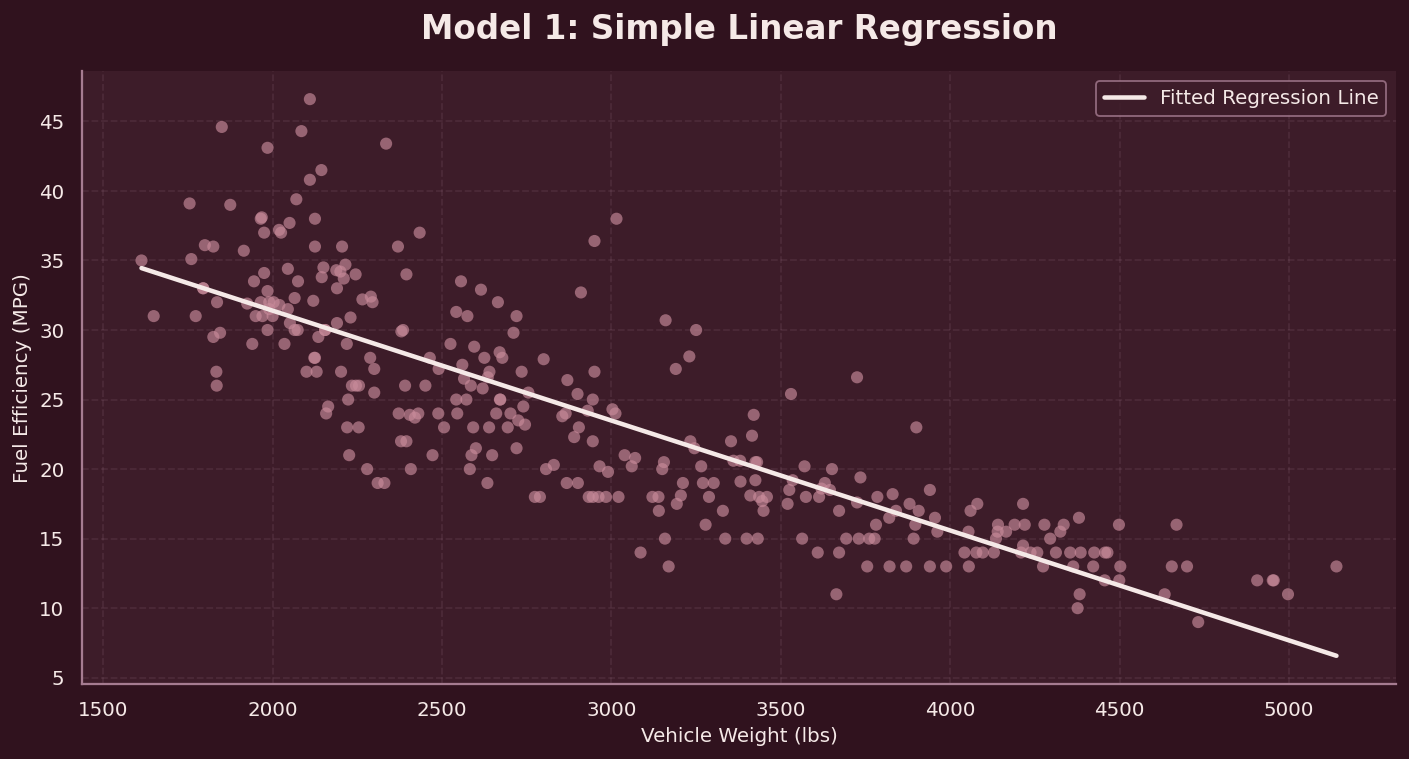

In [15]:
plt.figure(figsize=(11, 6))

sns.regplot(
    x=X_train["weight"],
    y=y_train,
    ci=None,
    scatter_kws={
        "color": ROSE,
        "alpha": 0.65,
        "s": 45,
        "edgecolor": "none"
    },
    line_kws={
        "color": IVORY,
        "linewidth": 2.5,
        "label": "Fitted Regression Line"
    }
)

plt.title(
    "Model 1: Simple Linear Regression",
    fontsize=18,
    pad=18
)

plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Fuel Efficiency (MPG)")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
ci = model1.conf_int(alpha=alpha)

coef_table = pd.DataFrame({
    "Coefficient": model1.params,
    "Standard Error": model1.bse,
    "t-statistic": model1.tvalues,
    "p-value": model1.pvalues,
    "95% CI Lower": ci[0],
    "95% CI Upper": ci[1],
    "Significant": np.where(
        model1.pvalues < alpha, "Yes", "No"
    )
})

display(coef_table.round(6))

print(f"R-squared: {model1.rsquared:.4f}")
print(f"Adjusted R-squared: {model1.rsquared_adj:.4f}")
print(f"F-statistic: {model1.fvalue:.4f}")
print(f"Model p-value: {model1.f_pvalue:.4e}")

,Coefficient,Standard Error,t-statistic,p-value,95% CI Lower,95% CI Upper,Significant
const,47.200526,0.914067,51.637922,0.0,45.401989,48.999064,Yes
weight,-0.007904,0.000295,-26.821577,0.0,-0.008483,-0.007324,Yes


R-squared: 0.6982
Adjusted R-squared: 0.6972
F-statistic: 719.3970
Model p-value: 6.8337e-83


## 2.3 Model 2: Multiple Linear Regression (Full Model)

Multiple Linear Regression examines the simultaneous relationship between several independent variables and fuel efficiency.

Unlike simple linear regression, each coefficient represents the expected change in MPG associated with a one-unit increase in the corresponding predictor, holding all other predictors constant (ceteris paribus).

### Model Equation

$$MPG_i = \beta_0 + \sum_{j=1}^{8}\beta_j X_{ij} + \epsilon_i$$

### Overall Model Significance (F-test)

- H₀: All slope coefficients are zero.
- H₁: At least one slope coefficient is non-zero.

### Individual Predictor Significance (t-test)

- H₀: βⱼ = 0
- H₁: βⱼ ≠ 0

Significance level: α = 0.05.

The full model establishes a comprehensive baseline for evaluating predictor significance, explanatory power and potential multicollinearity.

In [17]:
# Model 2: Multiple Linear Regression
X_train_m2 = sm.add_constant(X_train)

model2 = sm.OLS(y_train, X_train_m2).fit()

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.824
Method:                 Least Squares   F-statistic:                     183.8
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          1.20e-111
Time:                        11:54:26   Log-Likelihood:                -816.67
No. Observations:                 313   AIC:                             1651.
Df Residuals:                     304   BIC:                             1685.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -19.3319      5.446     -3.550

In [18]:
ci_m2 = model2.conf_int(alpha=alpha)

coef_table_m2 = pd.DataFrame({
    "Coefficient": model2.params,
    "Standard Error": model2.bse,
    "t-statistic": model2.tvalues,
    "p-value": model2.pvalues,
    "95% CI Lower": ci_m2[0],
    "95% CI Upper": ci_m2[1],
    "Significant": np.where(
        model2.pvalues < alpha, "Yes", "No"
    )
})

display(coef_table_m2.round(6))

,Coefficient,Standard Error,t-statistic,p-value,95% CI Lower,95% CI Upper,Significant
const,-19.331930,5.445952,-3.549780,0.000447,-30.048464,-8.615397,Yes
cylinders,-0.342101,0.370407,-0.923583,0.356436,-1.070987,0.386784,No
displacement,0.019206,0.008644,2.221854,0.027029,0.002196,0.036216,Yes
horsepower,-0.021620,0.015547,-1.390674,0.165342,-0.052213,0.008972,No
weight,-0.006423,0.000727,-8.832784,0.000000,-0.007854,-0.004992,Yes
acceleration,0.042198,0.109789,0.384358,0.700982,-0.173844,0.258240,No
model_year,0.797161,0.060407,13.196410,0.000000,0.678292,0.916031,Yes
origin_europe,2.875499,0.655978,4.383530,0.000016,1.584667,4.166332,Yes
origin_japan,3.205969,0.619803,5.172558,0.000000,1.986321,4.425617,Yes


In [19]:
model_comparison = pd.DataFrame({
    "Model": ["Simple Regression", "Multiple Regression"],
    "Number of Predictors": [1, 8],
    "R-squared": [model1.rsquared, model2.rsquared],
    "Adjusted R-squared": [
        model1.rsquared_adj,
        model2.rsquared_adj
    ],
    "F-statistic": [model1.fvalue, model2.fvalue],
    "Model p-value": [model1.f_pvalue, model2.f_pvalue]
})

display(model_comparison.round(4))

,Model,Number of Predictors,R-squared,Adjusted R-squared,F-statistic,Model p-value
0,Simple Regression,1,0.6982,0.6972,719.3970,0.0
1,Multiple Regression,8,0.8287,0.8242,183.8156,0.0


### Interpretation of Models 1 and 2

#### Model Comparison

- Model 1 explains 69.82% of the variability in MPG.
- Model 2 explains 82.87% of the variability in MPG.
- Adjusted R-squared increases from 0.6972 to 0.8242, indicating improved explanatory power after accounting for the number of predictors.
- Both models are statistically significant according to their overall F-tests at the 5% significance level.

#### Individual Predictor Significance

Based on the conventional OLS t-tests:

Statistically significant predictors:
- Displacement
- Weight
- Model year
- European origin
- Japanese origin

Statistically insignificant predictors:
- Cylinders
- Horsepower
- Acceleration

#### Practical Interpretation of Coefficients

Holding all other predictors constant:

- A 100-pound increase in vehicle weight is associated with a decrease of approximately 0.6423 MPG.
- A one-year increase in model year is associated with an increase of approximately 0.7972 MPG.
- European vehicles have an estimated MPG that is 2.8755 units higher than American vehicles.
- Japanese vehicles have an estimated MPG that is 3.2060 units higher than American vehicles.

#### Preliminary Diagnostic Concerns

Displacement has a positive regression coefficient despite its negative marginal correlation with MPG. This sign reversal may arise from relationships among correlated predictors.

The large condition number (89,900) warrants further investigation of multicollinearity, although differences in predictor scales may also contribute.

The significant Jarque-Bera test indicates a departure from residual normality.

Therefore, the full model cannot yet be considered the final model. Further diagnostics and validation are required before drawing definitive statistical conclusions.

## 2.4 Multicollinearity Assessment

Multicollinearity occurs when independent variables are strongly related to one another, making it difficult to estimate their individual effects reliably.

The Variance Inflation Factor (VIF) measures the inflation in the variance of a regression coefficient due to relationships with other predictors.

$$VIF_j = \frac{1}{1-R_j^2}$$

Where $R_j^2$ is obtained by regressing predictor j on the remaining predictors.

The following diagnostic guidelines are adopted:

- VIF < 5: Low to moderate multicollinearity.
- 5 ≤ VIF < 10: Elevated multicollinearity.
- VIF ≥ 10: Severe multicollinearity.

These thresholds are diagnostic guidelines rather than absolute rules for predictor removal.

In [20]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(X_data):
    X_const = sm.add_constant(X_data).astype(float)

    vif = pd.DataFrame({
        "Predictor": X_const.columns,
        "VIF": [
            variance_inflation_factor(X_const.values, i)
            for i in range(X_const.shape[1])
        ]
    })

    vif = vif[vif["Predictor"] != "const"].copy()

    vif["Severity"] = np.select(
        [vif["VIF"] >= 10, vif["VIF"] >= 5],
        ["Severe", "Elevated"],
        default="Low to Moderate"
    )

    return vif.sort_values("VIF", ascending=False).reset_index(drop=True)

vif_full = calculate_vif(X_train)

display(vif_full.round(4))

,Predictor,VIF,Severity
0,displacement,22.5538,Severe
1,cylinders,11.1211,Severe
2,weight,10.4865,Severe
3,horsepower,9.9305,Elevated
4,acceleration,2.6830,Low to Moderate
5,origin_japan,1.7368,Low to Moderate
6,origin_europe,1.5712,Low to Moderate
7,model_year,1.3480,Low to Moderate


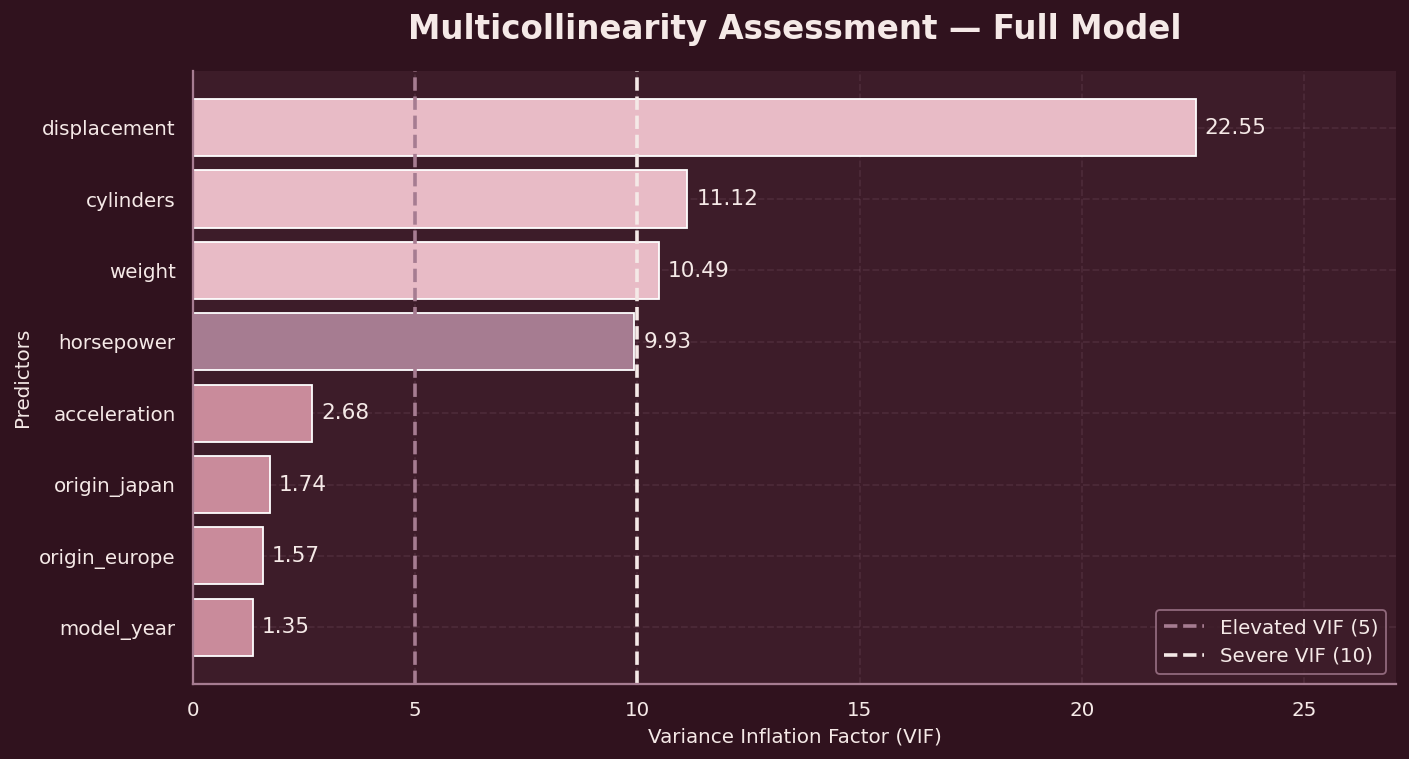

In [21]:
plt.figure(figsize=(11, 6))

colors = [
    PINK if v >= 10 else MAUVE if v >= 5 else ROSE
    for v in vif_full["VIF"]
]

bars = plt.barh(
    vif_full["Predictor"],
    vif_full["VIF"],
    color=colors
)

plt.axvline(
    5, color=MAUVE,
    linestyle="--", linewidth=2,
    label="Elevated VIF (5)"
)

plt.axvline(
    10, color=IVORY,
    linestyle="--", linewidth=2,
    label="Severe VIF (10)"
)

plt.bar_label(
    bars, fmt="%.2f",
    padding=5, color=IVORY
)

plt.gca().invert_yaxis()
plt.xlim(0, max(10, vif_full["VIF"].max()) * 1.2)

plt.title(
    "Multicollinearity Assessment — Full Model",
    fontsize=18, pad=18
)

plt.xlabel("Variance Inflation Factor (VIF)")
plt.ylabel("Predictors")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of VIF Results

Displacement exhibits the highest VIF (22.5538), followed by cylinders (11.1211) and weight (10.4865), confirming severe multicollinearity.

Horsepower also exhibits elevated multicollinearity, with a VIF of 9.9305.

Weight is prioritised for retention because of its strong association with MPG, statistical significance and practical relevance.

## 2.5 Model 3: Reduced Multiple Linear Regression

An iterative predictor elimination approach is adopted to address multicollinearity.

The predictor with the highest VIF is removed at each iteration, and VIF values are recalculated until all remaining predictors have VIF values below 5.

This approach aims to improve coefficient stability and model interpretability while preserving relevant explanatory information.

The reduced model will subsequently be compared with the full model to assess whether reducing multicollinearity results in a substantial loss of explanatory power.

In [22]:
selected_features = X_train.columns.tolist()
elimination_history = []

while True:

    current_vif = calculate_vif(X_train[selected_features])

    highest_vif = current_vif.iloc[0]["VIF"]
    highest_feature = current_vif.iloc[0]["Predictor"]

    if highest_vif < 5:
        break

    elimination_history.append({
        "Iteration": len(elimination_history) + 1,
        "Removed Predictor": highest_feature,
        "VIF Before Removal": highest_vif
    })

    selected_features.remove(highest_feature)

print("Predictor Elimination History:")
display(pd.DataFrame(elimination_history).round(4))

print("\nRetained Predictors:")
print(selected_features)

print("\nVIF After Elimination:")
vif_reduced = calculate_vif(X_train[selected_features])
display(vif_reduced.round(4))

Predictor Elimination History:


,Iteration,Removed Predictor,VIF Before Removal
0,1,displacement,22.5538
1,2,horsepower,9.2239
2,3,cylinders,6.0437



Retained Predictors:
['weight', 'acceleration', 'model_year', 'origin_europe', 'origin_japan']

VIF After Elimination:


,Predictor,VIF,Severity
0,weight,1.8205,Low to Moderate
1,origin_japan,1.5095,Low to Moderate
2,origin_europe,1.3032,Low to Moderate
3,acceleration,1.2520,Low to Moderate
4,model_year,1.2018,Low to Moderate


In [23]:
X_train_m3 = sm.add_constant(X_train[selected_features])

model3 = sm.OLS(y_train, X_train_m3).fit()

print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.822
Method:                 Least Squares   F-statistic:                     290.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          5.48e-114
Time:                        11:54:28   Log-Likelihood:                -819.76
No. Observations:                 313   AIC:                             1652.
Df Residuals:                     307   BIC:                             1674.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -20.8178      4.673     -4.455

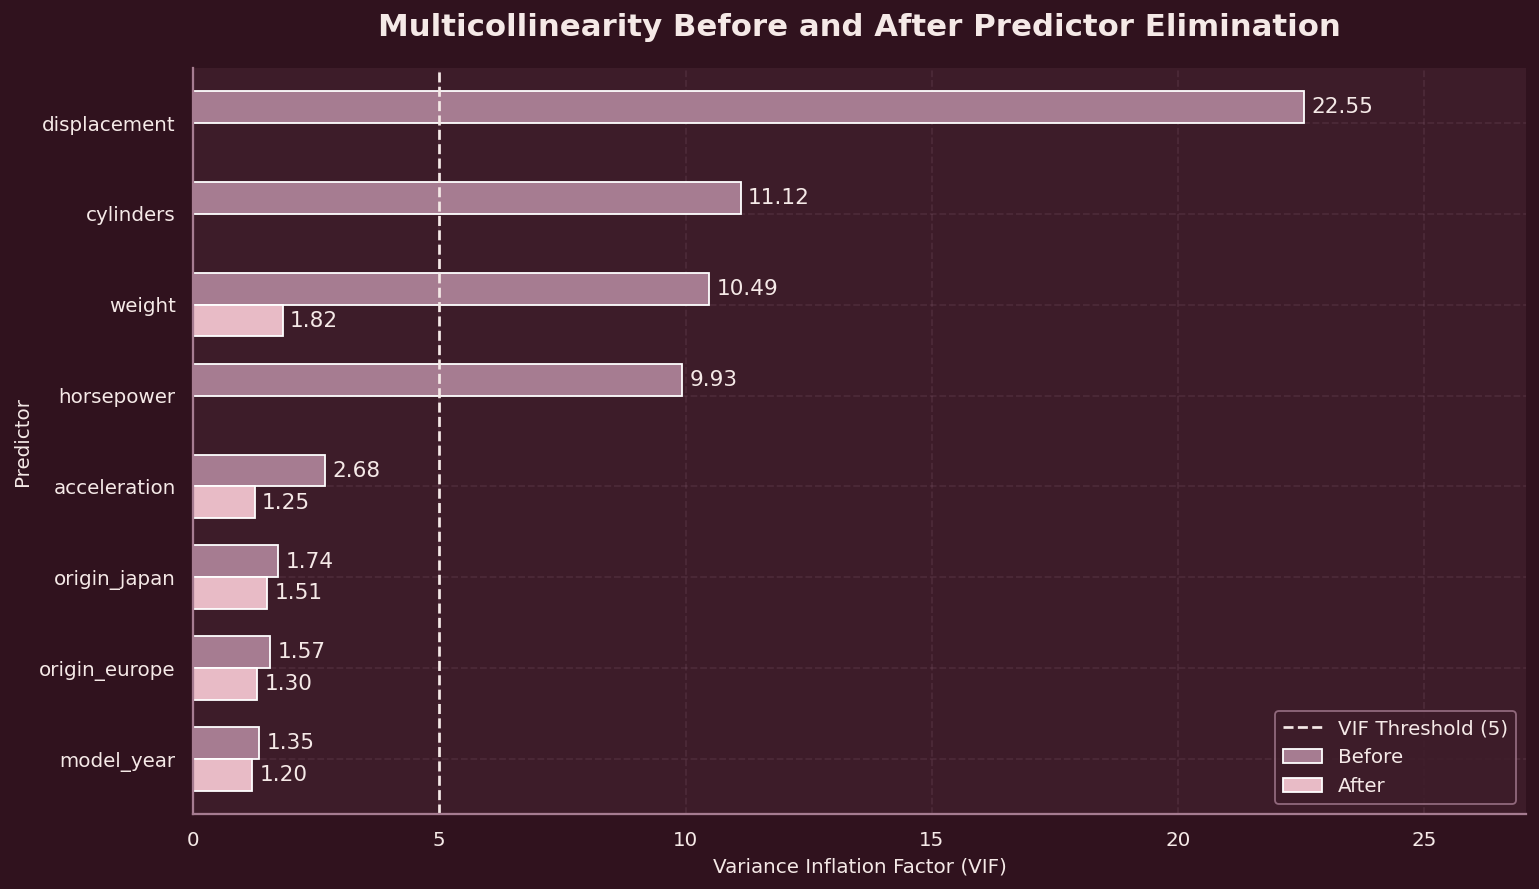

,Predictor,VIF_Before,VIF_After
0,displacement,22.5538,Removed
1,cylinders,11.1211,Removed
2,weight,10.4865,1.8205
3,horsepower,9.9305,Removed
4,acceleration,2.6830,1.252
5,origin_japan,1.7368,1.5095
6,origin_europe,1.5712,1.3032
7,model_year,1.3480,1.2018


In [24]:
vif_comparison = vif_full[["Predictor", "VIF"]].merge(
    vif_reduced[["Predictor", "VIF"]],
    on="Predictor",
    how="left",
    suffixes=("_Before", "_After")
)

plot_data = vif_comparison.set_index("Predictor")

ax = plot_data.plot(
    kind="barh",
    figsize=(12, 7),
    color=[MAUVE, PINK],
    width=0.7
)

ax.axvline(
    5, color=IVORY,
    linestyle="--",
    label="VIF Threshold (5)"
)

ax.invert_yaxis()

for container in ax.containers:
    labels = [
        f"{v:.2f}" if v > 0 else ""
        for v in container.datavalues
    ]
    ax.bar_label(container, labels=labels,
                 padding=4, color=IVORY)

ax.set_title(
    "Multicollinearity Before and After Predictor Elimination",
    fontsize=17, pad=18
)

ax.set_xlabel("Variance Inflation Factor (VIF)")
ax.set_ylabel("Predictor")
ax.set_xlim(0, vif_full["VIF"].max() * 1.2)

ax.legend(["VIF Threshold (5)", "Before", "After"])

plt.tight_layout()
plt.show()

display(vif_comparison.round(4).fillna("Removed"))

### Interpretation of the Reduced Model

- Displacement, horsepower and cylinders were eliminated iteratively to address multicollinearity.
- The maximum VIF decreased from 22.5538 to 1.8205.
- R-squared decreased only marginally from 0.8287 to approximately 0.825.
- Adjusted R-squared remained approximately 0.822, indicating that most explanatory power has been preserved.
- BIC decreased from 1685 to 1674, supporting a more parsimonious model.
- Weight, model year and both origin indicators remain statistically significant under conventional OLS inference.
- Acceleration remains statistically insignificant (p = 0.383).
- Residual normality remains a concern, as indicated by the significant Jarque-Bera test.

The reduced model provides improved coefficient stability with minimal loss of explanatory power. However, further model refinement and assumption testing are necessary.

## 2.6 Model 4: Parsimonious Multiple Linear Regression

Acceleration remains statistically insignificant after addressing multicollinearity.

An additional model is developed by excluding acceleration while retaining weight, model year and the origin indicators.

A partial F-test is conducted to compare Models 3 and 4.

### Hypotheses

- H₀: Removing acceleration does not significantly reduce model fit.
- H₁: Removing acceleration significantly reduces model fit.

Significance level: α = 0.05.

This comparison evaluates whether the additional predictor provides sufficient explanatory value to justify the increased model complexity.

In [25]:
features_m4 = [
    "weight",
    "model_year",
    "origin_europe",
    "origin_japan"
]

X_train_m4 = sm.add_constant(X_train[features_m4])

model4 = sm.OLS(y_train, X_train_m4).fit()

print(model4.summary())

print("\nVIF Assessment:")
display(calculate_vif(X_train[features_m4]).round(4))

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     362.6
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          3.95e-115
Time:                        11:54:29   Log-Likelihood:                -820.15
No. Observations:                 313   AIC:                             1650.
Df Residuals:                     308   BIC:                             1669.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -20.4216      4.649     -4.393

,Predictor,VIF,Severity
0,weight,1.7015,Low to Moderate
1,origin_japan,1.5086,Low to Moderate
2,origin_europe,1.2886,Low to Moderate
3,model_year,1.1457,Low to Moderate


In [26]:
from statsmodels.stats.anova import anova_lm

print("Partial F-test: Model 4 vs Model 3")

partial_f = anova_lm(model4, model3)
display(partial_f)

p_value = partial_f["Pr(>F)"].iloc[1]

print(f"p-value: {p_value:.6f}")

if p_value < alpha:
    print("Reject H0: Acceleration significantly improves model fit.")
else:
    print("Fail to reject H0: There is insufficient evidence that acceleration improves model fit.")

Partial F-test: Model 4 vs Model 3


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,308.0,3459.480187,0.0,NaN,NaN,NaN
1,307.0,3450.903109,1.0,8.577078,0.763036,0.383063


p-value: 0.383063
Fail to reject H0: There is insufficient evidence that acceleration improves model fit.


In [27]:
models = {
    "M1 - Simple": model1,
    "M2 - Full": model2,
    "M3 - Reduced": model3,
    "M4 - Parsimonious": model4
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "Predictors": int(model.df_model),
        "R-squared": model.rsquared,
        "Adjusted R-squared": model.rsquared_adj,
        "AIC": model.aic,
        "BIC": model.bic,
        "F-statistic": model.fvalue,
        "Model p-value": f"{model.f_pvalue:.3e}"
    }
    for name, model in models.items()
])

display(comparison.round(4))

,Model,Predictors,R-squared,Adjusted R-squared,AIC,BIC,F-statistic,Model p-value
0,M1 - Simple,1,0.6982,0.6972,1814.6071,1822.0995,719.3970,6.834e-83
1,M2 - Full,8,0.8287,0.8242,1651.3383,1685.0542,183.8156,1.196e-111
2,M3 - Reduced,5,0.8253,0.8224,1651.5144,1673.9916,290.0047,5.483e-114
3,M4 - Parsimonious,4,0.8248,0.8226,1650.2914,1669.0224,362.5941,3.953e-115


### Interpretation of Model 4 and Model Comparison

- The partial F-test produces an F-statistic of 0.7630 and a p-value of 0.3831.
- Since the p-value exceeds 0.05, the null hypothesis is not rejected. There is insufficient evidence that acceleration improves model fit.
- Removing acceleration increases adjusted R-squared slightly from 0.8224 to 0.8226.
- Model 4 explains 82.48% of the variation in MPG using only four predictors.
- Model 4 achieves the lowest AIC (1650.29) and BIC (1669.02), supporting its parsimony.
- All retained predictors are statistically significant under conventional OLS inference.
- The maximum VIF is 1.7015, indicating no concerning multicollinearity among the retained predictors.

Model 4 is provisionally preferred because it balances explanatory power, simplicity and coefficient interpretability.

However, final model selection requires regression assumption assessment and predictive validation.

## 2.7 Regression Diagnostics and Assumption Testing

The reliability of regression-based statistical inference depends on the underlying model assumptions.

The following aspects are examined:

1. Linearity: Residuals versus fitted values plot.
2. Normality: Residual histogram, Q-Q plot and Jarque-Bera test.
3. Homoscedasticity: Residual plots and Breusch-Pagan test.
4. Independence: Study design and Durbin-Watson statistic.
5. Multicollinearity: Previously assessed using VIF.
6. Influential observations: Cook's distance.

Model 4 is initially examined because it is the preferred candidate based on the preceding model comparison.

A significance level of 0.05 is used for formal diagnostic tests.

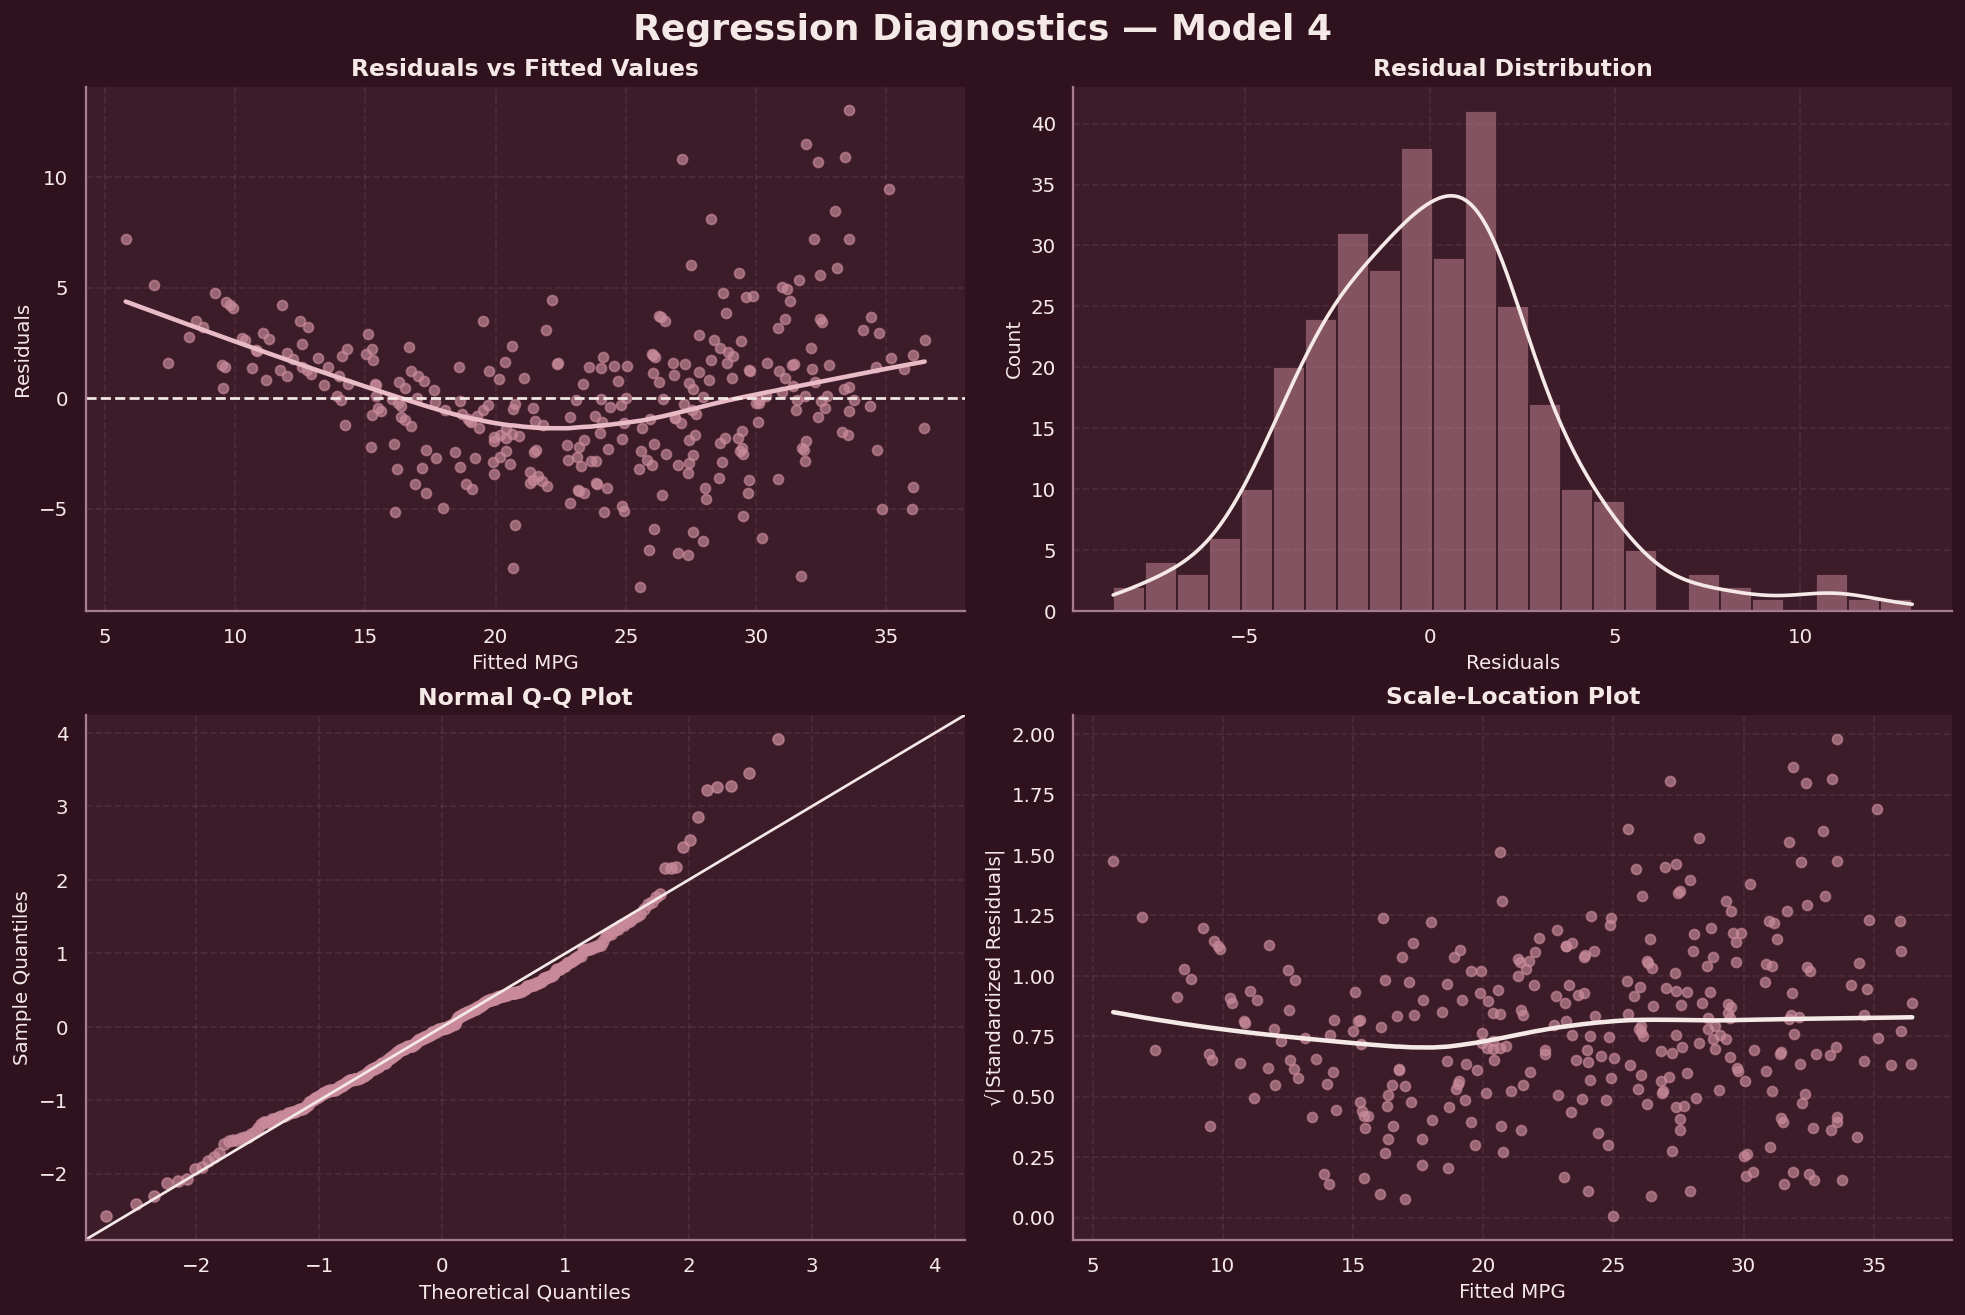

In [28]:
fitted = model4.fittedvalues
residuals = model4.resid

influence = model4.get_influence()
std_residuals = influence.resid_studentized_internal
cooks_distance = influence.cooks_distance[0]

fig, axes = plt.subplots(
    2, 2, figsize=(15, 10),
    constrained_layout=True
)

# 1. Residuals vs Fitted
sns.regplot(
    x=fitted,
    y=residuals,
    lowess=True,
    scatter_kws={"color": ROSE, "alpha": 0.65, "s": 30},
    line_kws={"color": PINK, "linewidth": 2.5},
    ax=axes[0, 0]
)

axes[0, 0].axhline(0, color=IVORY, linestyle="--")
axes[0, 0].set_title("Residuals vs Fitted Values")
axes[0, 0].set_xlabel("Fitted MPG")
axes[0, 0].set_ylabel("Residuals")

# 2. Residual distribution
sns.histplot(
    residuals,
    kde=True,
    bins=25,
    color=ROSE,
    edgecolor=PANEL,
    ax=axes[0, 1]
)

for line in axes[0, 1].lines:
    line.set_color(IVORY)
    line.set_linewidth(2)

axes[0, 1].set_title("Residual Distribution")
axes[0, 1].set_xlabel("Residuals")

# 3. Normal Q-Q plot
sm.qqplot(
    residuals,
    line="45",
    fit=True,
    ax=axes[1, 0],
    markerfacecolor=ROSE,
    markeredgecolor=ROSE,
    alpha=0.7
)

axes[1, 0].lines[-1].set_color(IVORY)
axes[1, 0].set_title("Normal Q-Q Plot")

# 4. Scale-location plot
sns.regplot(
    x=fitted,
    y=np.sqrt(np.abs(std_residuals)),
    lowess=True,
    scatter_kws={"color": ROSE, "alpha": 0.65, "s": 30},
    line_kws={"color": IVORY, "linewidth": 2.5},
    ax=axes[1, 1]
)

axes[1, 1].set_title("Scale-Location Plot")
axes[1, 1].set_xlabel("Fitted MPG")
axes[1, 1].set_ylabel("√|Standardized Residuals|")

fig.suptitle(
    "Regression Diagnostics — Model 4",
    fontsize=20,
    fontweight="bold",
    color=IVORY
)

plt.show()

In [29]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera, durbin_watson

# Normality test
jb_stat, jb_p, skew, kurtosis = jarque_bera(residuals)

# Homoscedasticity test
bp_stat, bp_p, bp_f, bp_f_p = het_breuschpagan(
    residuals,
    model4.model.exog
)

# Residual autocorrelation
dw_stat = durbin_watson(residuals)

diagnostic_results = pd.DataFrame({
    "Assumption": [
        "Normality",
        "Homoscedasticity"
    ],
    "Test": [
        "Jarque-Bera",
        "Breusch-Pagan"
    ],
    "Test Statistic": [jb_stat, bp_stat],
    "p-value": [f"{jb_p:.4e}", f"{bp_p:.4e}"],
    "Decision": [
        "Reject H0" if jb_p < alpha else "Fail to reject H0",
        "Reject H0" if bp_p < alpha else "Fail to reject H0"
    ]
})

display(diagnostic_results)

print(f"Durbin-Watson statistic: {dw_stat:.4f}")
print(f"Residual skewness: {skew:.4f}")
print(f"Residual kurtosis: {kurtosis:.4f}")

,Assumption,Test,Test Statistic,p-value,Decision
0,Normality,Jarque-Bera,43.959119,2.8471e-10,Reject H0
1,Homoscedasticity,Breusch-Pagan,25.616301,3.7812e-05,Reject H0


Durbin-Watson statistic: 2.0009
Residual skewness: 0.5783
Residual kurtosis: 4.4257


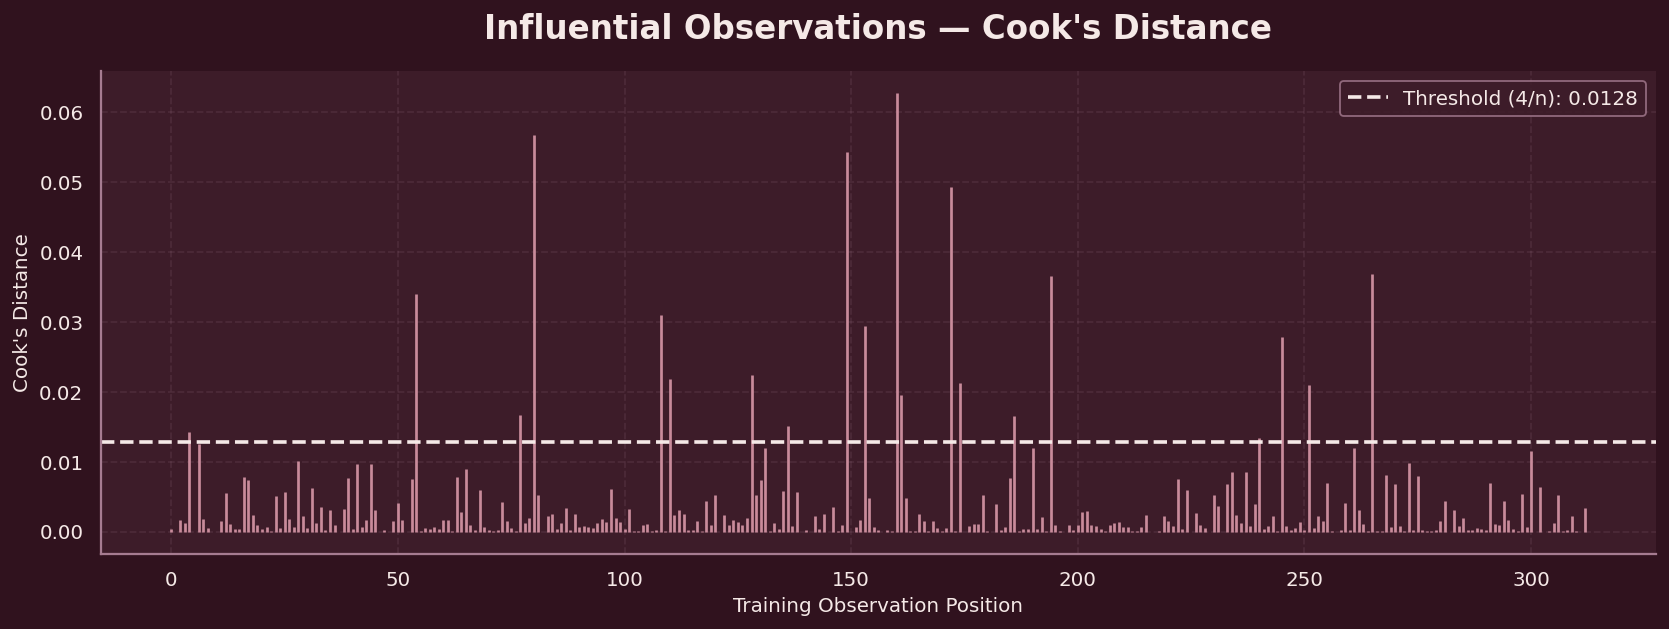

Potentially influential observations: 20
Maximum Cook's distance: 0.0628


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,Actual MPG,Cook's Distance
324,4,90.0,48.0,2335,23.7,80,1,0,43.4,0.0628
323,4,90.0,48.0,2085,21.7,80,1,0,44.3,0.0568
320,4,86.0,65.0,2110,17.9,80,0,1,46.6,0.0543
242,4,90.0,48.0,1985,21.5,78,1,0,43.1,0.0494
273,6,163.0,125.0,3140,13.6,78,1,0,17.0,0.0369
325,5,121.0,67.0,2950,19.9,80,1,0,36.4,0.0365
307,4,98.0,76.0,2144,14.7,80,1,0,41.5,0.0340
381,6,262.0,85.0,3015,17.0,82,0,0,38.0,0.0310
327,4,91.0,67.0,1850,13.8,80,0,1,44.6,0.0294
43,8,400.0,175.0,5140,12.0,71,0,0,13.0,0.0279


In [30]:
threshold = 4 / len(X_train)

plt.figure(figsize=(13, 5))

plt.stem(
    np.arange(len(cooks_distance)),
    cooks_distance,
    linefmt=ROSE,
    markerfmt=" ",
    basefmt=" "
)

plt.axhline(
    threshold,
    color=IVORY,
    linestyle="--",
    linewidth=2,
    label=f"Threshold (4/n): {threshold:.4f}"
)

plt.title("Influential Observations — Cook's Distance",
          fontsize=18, pad=18)

plt.xlabel("Training Observation Position")
plt.ylabel("Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

influential_mask = cooks_distance > threshold

print("Potentially influential observations:",
      influential_mask.sum())

print("Maximum Cook's distance:",
      round(cooks_distance.max(), 4))

influential_data = X_train.loc[influential_mask].copy()
influential_data["Actual MPG"] = y_train.loc[influential_mask]
influential_data["Cook's Distance"] = cooks_distance[influential_mask]

display(
    influential_data.sort_values(
        "Cook's Distance", ascending=False
    ).head(10).round(4)
)

### Interpretation of Regression Diagnostics

#### Normality

The Jarque-Bera test produces a p-value of 2.8471 × 10⁻¹⁰. Since the p-value is below 0.05, the null hypothesis of normally distributed errors is rejected.

Residual skewness (0.5783) and kurtosis (4.4257) indicate positive skewness and heavier tails than a normal distribution.

#### Homoscedasticity

The Breusch-Pagan test produces a p-value of 0.0000378. The null hypothesis of constant error variance is rejected, indicating heteroscedasticity.

Consequently, conventional OLS standard errors, hypothesis tests and confidence intervals may be unreliable.

#### Independence

The Durbin-Watson statistic is approximately 2. However, because the observations were randomly shuffled during the training split, this result does not establish independence.

#### Multicollinearity

All retained predictors have VIF values below 2, indicating no concerning multicollinearity.

#### Influential Observations

Cook's distance identifies 20 potentially influential observations using the 4/n screening threshold.

The maximum Cook's distance is 0.0628. The flagged observations will be retained initially because they represent plausible automobile characteristics. Their influence will be investigated through sensitivity analysis.

#### Corrective Measures

A logarithmic transformation of MPG will be investigated to determine whether it improves residual normality and stabilises error variance.

## 2.8 Model Refinement Using Log Transformation

A logarithmic transformation of the dependent variable is investigated to address heteroscedasticity and residual non-normality.

The same four predictors from Model 4 are retained to isolate the effect of transforming the dependent variable.

### Model Equation

$$\ln(MPG_i) = \beta_0 + \beta_1 Weight_i + \beta_2 ModelYear_i + \beta_3 OriginEurope_i + \beta_4 OriginJapan_i + \epsilon_i$$

The transformed model remains a multiple linear regression model because it is linear in its parameters.

Diagnostic tests are repeated to determine whether the transformation improves model assumptions.

In [31]:
y_train_log = np.log(y_train)

model5 = sm.OLS(y_train_log, X_train_m4).fit()

print(model5.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     555.3
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          2.03e-139
Time:                        11:54:32   Log-Likelihood:                 219.10
No. Observations:                 313   AIC:                            -428.2
Df Residuals:                     308   BIC:                            -409.5
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             1.3490      0.168      8.028

In [32]:
def get_diagnostics(model):
    jb_stat, jb_p, skew, kurtosis = jarque_bera(model.resid)

    bp_stat, bp_p, _, _ = het_breuschpagan(
        model.resid,
        model.model.exog
    )

    return {
        "JB Statistic": jb_stat,
        "JB p-value": jb_p,
        "BP Statistic": bp_stat,
        "BP p-value": bp_p,
        "Residual Skewness": skew,
        "Residual Kurtosis": kurtosis,
        "Durbin-Watson": durbin_watson(model.resid)
    }

diagnostic_comparison = pd.DataFrame({
    "Model 4 - Original MPG": get_diagnostics(model4),
    "Model 5 - Log MPG": get_diagnostics(model5)
}).T

display(diagnostic_comparison)

,JB Statistic,JB p-value,BP Statistic,BP p-value,Residual Skewness,Residual Kurtosis,Durbin-Watson
Model 4 - Original MPG,43.959119,2.847073e-10,25.616301,0.000038,0.578343,4.425743,2.000908
Model 5 - Log MPG,6.495841,3.885492e-02,9.379345,0.052286,-0.201038,3.580017,1.955260


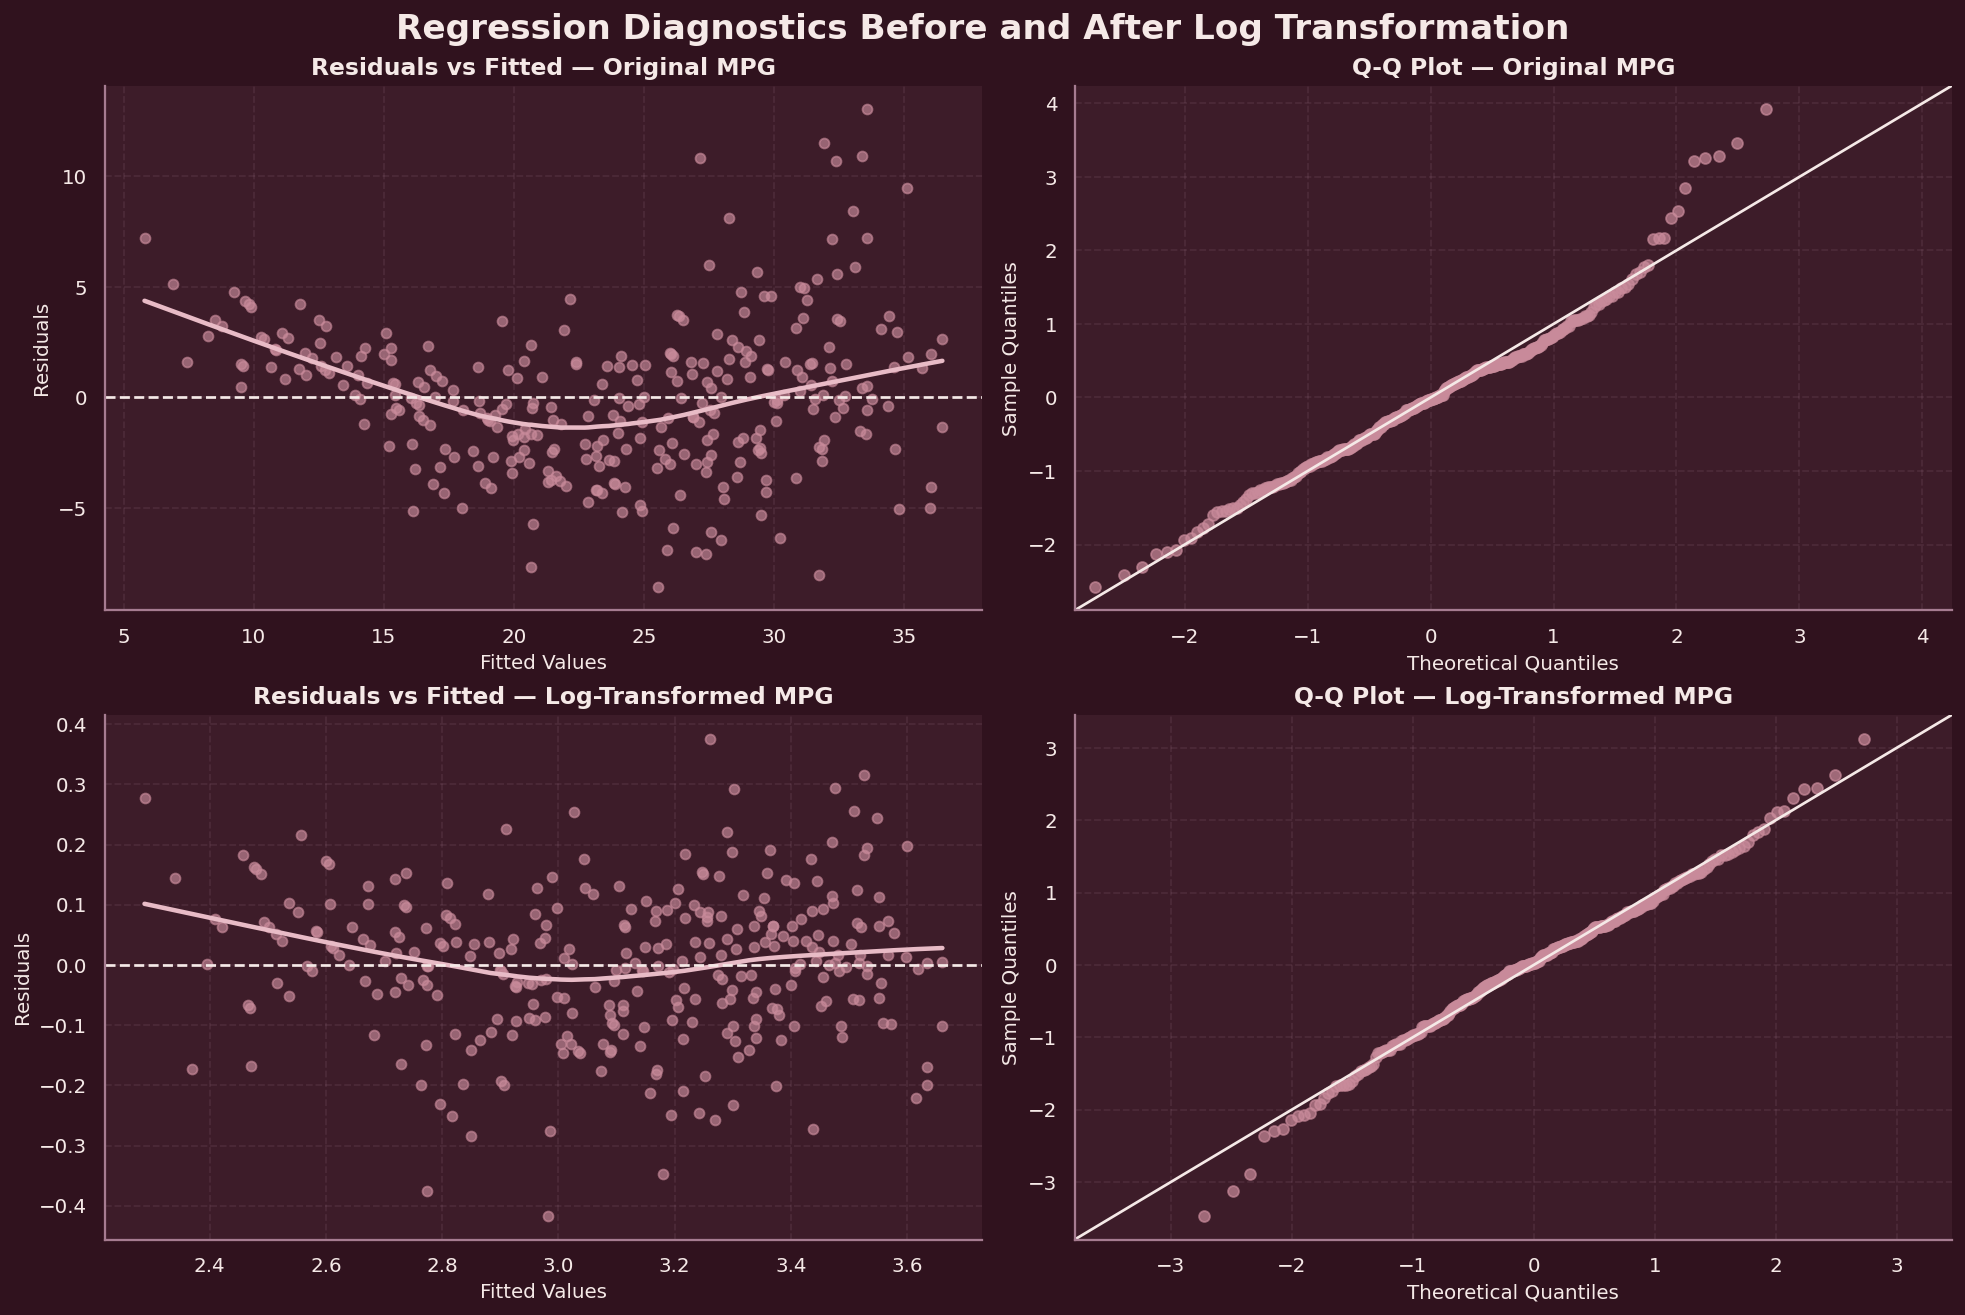

In [33]:
fig, axes = plt.subplots(
    2, 2, figsize=(15, 10),
    constrained_layout=True
)

for i, (model, title) in enumerate([
    (model4, "Original MPG"),
    (model5, "Log-Transformed MPG")
]):

    sns.regplot(
        x=model.fittedvalues,
        y=model.resid,
        lowess=True,
        scatter_kws={
            "color": ROSE,
            "alpha": 0.65,
            "s": 30
        },
        line_kws={
            "color": PINK,
            "linewidth": 2.5
        },
        ax=axes[i, 0]
    )

    axes[i, 0].axhline(
        0, color=IVORY, linestyle="--"
    )

    axes[i, 0].set_title(f"Residuals vs Fitted — {title}")
    axes[i, 0].set_xlabel("Fitted Values")
    axes[i, 0].set_ylabel("Residuals")

    sm.qqplot(
        model.resid,
        line="45",
        fit=True,
        markerfacecolor=ROSE,
        markeredgecolor=ROSE,
        alpha=0.7,
        ax=axes[i, 1]
    )

    axes[i, 1].lines[-1].set_color(IVORY)
    axes[i, 1].set_title(f"Q-Q Plot — {title}")

fig.suptitle(
    "Regression Diagnostics Before and After Log Transformation",
    fontsize=19,
    fontweight="bold",
    color=IVORY
)

plt.show()

## 2.9 Robust Statistical Inference

Heteroscedasticity can lead to unreliable conventional standard errors, hypothesis tests and confidence intervals.

HC3 heteroscedasticity-consistent standard errors are therefore applied to Model 4.

This adjustment improves the reliability of statistical inference without changing the estimated regression coefficients, fitted values or R-squared.

However, robust standard errors do not eliminate heteroscedasticity or correct model misspecification.

In [34]:
model4_robust = model4.get_robustcov_results(cov_type="HC3")

robust_comparison = pd.DataFrame({
    "Coefficient": model4.params,
    "OLS Standard Error": model4.bse,
    "Robust Standard Error": model4_robust.bse,
    "OLS p-value": model4.pvalues,
    "Robust p-value": model4_robust.pvalues,
    "Significant (HC3)": np.where(
        model4_robust.pvalues < alpha, "Yes", "No"
    )
})

display(robust_comparison.round(6))

print(model4_robust.summary())

,Coefficient,OLS Standard Error,Robust Standard Error,OLS p-value,Robust p-value,Significant (HC3)
const,-20.421635,4.649065,4.466986,0.000015,0.000007,Yes
weight,-0.005926,0.000294,0.000276,0.000000,0.000000,Yes
model_year,0.798209,0.055946,0.055789,0.000000,0.000000,Yes
origin_europe,2.319244,0.596780,0.752593,0.000125,0.002244,Yes
origin_japan,2.644819,0.580296,0.630701,0.000007,0.000036,Yes


                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.825
Model:                            OLS   Adj. R-squared:                  0.823
Method:                 Least Squares   F-statistic:                     318.6
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          4.34e-108
Time:                        11:54:34   Log-Likelihood:                -820.15
No. Observations:                 313   AIC:                             1650.
Df Residuals:                     308   BIC:                             1669.
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -20.4216      4.467     -4.572

## 2.10 Sensitivity Analysis of Influential Observations

The Cook's distance analysis identified 20 potentially influential observations.

To assess coefficient stability, Model 4 is temporarily refitted after excluding these observations.

The resulting coefficients are compared with those obtained using the complete training dataset.

This exclusion is performed solely for sensitivity analysis. Valid observations are not permanently removed merely because they are influential.

In [35]:
model4_sensitivity = sm.OLS(
    y_train.loc[~influential_mask],
    X_train_m4.loc[~influential_mask]
).fit()

sensitivity_comparison = pd.DataFrame({
    "Original Coefficient": model4.params,
    "Sensitivity Coefficient": model4_sensitivity.params
})

sensitivity_comparison["Absolute Change (%)"] = (
    (
        sensitivity_comparison["Sensitivity Coefficient"]
        - sensitivity_comparison["Original Coefficient"]
    ).abs()
    / sensitivity_comparison["Original Coefficient"].abs()
) * 100

display(sensitivity_comparison.round(6))

print("Original observations:", int(model4.nobs))
print("Sensitivity observations:", int(model4_sensitivity.nobs))

,Original Coefficient,Sensitivity Coefficient,Absolute Change (%)
const,-20.421635,-15.544725,23.881093
weight,-0.005926,-0.005783,2.412846
model_year,0.798209,0.726005,9.045669
origin_europe,2.319244,1.827052,21.222101
origin_japan,2.644819,2.774286,4.895102


Original observations: 313
Sensitivity observations: 293


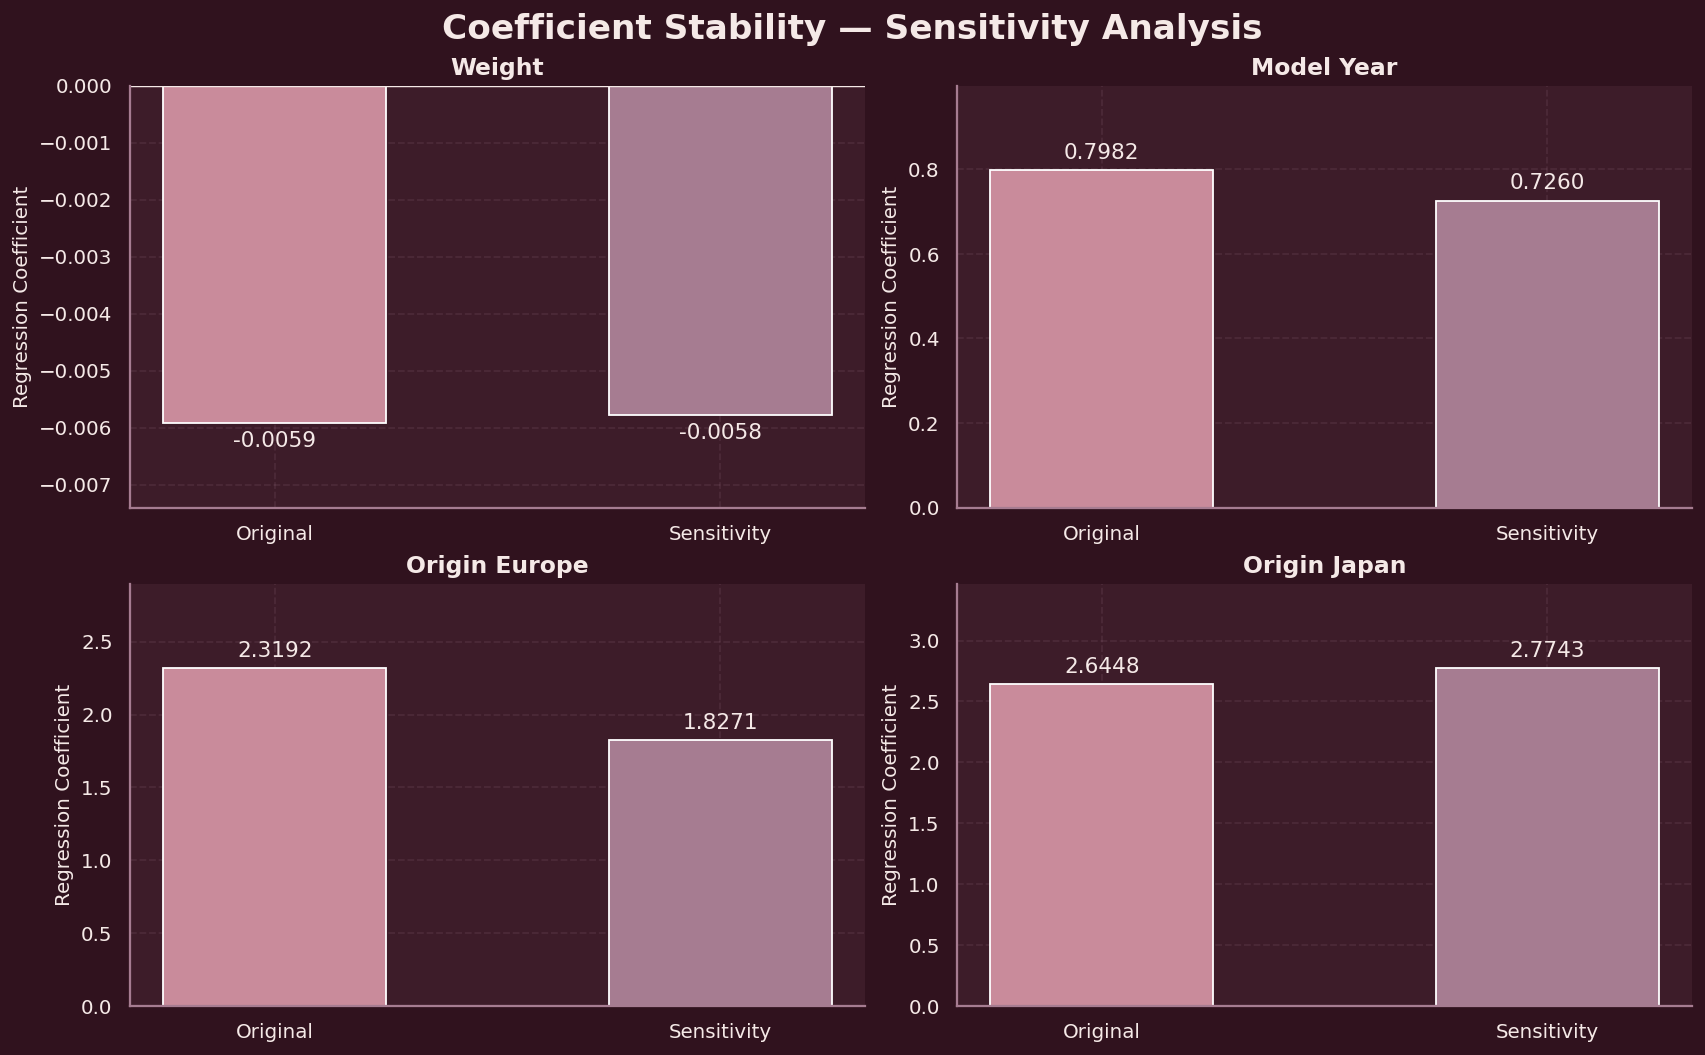

In [36]:
plot_data = sensitivity_comparison[
    ["Original Coefficient", "Sensitivity Coefficient"]
].drop(index="const")

fig, axes = plt.subplots(
    2, 2, figsize=(13, 8),
    constrained_layout=True
)

for ax, (feature, values) in zip(
    axes.flat, plot_data.iterrows()
):
    bars = ax.bar(
        ["Original", "Sensitivity"],
        values.values,
        color=[ROSE, MAUVE],
        width=0.5
    )

    ax.bar_label(
        bars, fmt="%.4f",
        padding=4, color=IVORY
    )

    ax.axhline(0, color=IVORY, linewidth=0.8)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel("Regression Coefficient")
    ax.margins(y=0.25)

fig.suptitle(
    "Coefficient Stability — Sensitivity Analysis",
    fontsize=19,
    fontweight="bold"
)

plt.show()

## 2.11 Cross-Validation and Predictive Performance

Five-fold cross-validation is employed to evaluate the predictive performance and generalisation ability of the candidate regression models.

The training dataset is divided into five folds. Each model is trained on four folds and validated on the remaining fold.

The following evaluation metrics are used:

- MAE: Mean Absolute Error.
- RMSE: Root Mean Squared Error.
- R-squared: Proportion of variation explained.

Lower MAE and RMSE and higher R-squared indicate better predictive performance.

For the log-transformed model, predictions are converted back to the original MPG scale using Duan's smearing correction to account for back-transformation bias.

The same validation folds are used for all models to ensure consistent comparison.

In [37]:
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

candidate_features = {
    "M1 - Simple": ["weight"],
    "M2 - Full": X_train.columns.tolist(),
    "M3 - Reduced": selected_features,
    "M4 - Parsimonious": features_m4,
    "M5 - Log Transformed": features_m4
}

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, features in candidate_features.items():

    for fold, (train_idx, val_idx) in enumerate(
        kf.split(X_train), start=1
    ):

        X_tr = sm.add_constant(
            X_train.iloc[train_idx][features],
            has_constant="add"
        )

        X_val = sm.add_constant(
            X_train.iloc[val_idx][features],
            has_constant="add"
        )

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        if name == "M5 - Log Transformed":

            fitted_model = sm.OLS(
                np.log(y_tr), X_tr
            ).fit()

            smearing_factor = np.mean(
                np.exp(fitted_model.resid)
            )

            predictions = (
                np.exp(fitted_model.predict(X_val))
                * smearing_factor
            )

        else:

            fitted_model = sm.OLS(y_tr, X_tr).fit()
            predictions = fitted_model.predict(X_val)

        cv_results.append({
            "Model": name,
            "Fold": fold,
            "MAE": mean_absolute_error(y_val, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_val, predictions)
            ),
            "R-squared": r2_score(y_val, predictions)
        })

cv_results = pd.DataFrame(cv_results)

cv_summary = cv_results.groupby("Model").agg(
    Mean_MAE=("MAE", "mean"),
    Mean_RMSE=("RMSE", "mean"),
    RMSE_SD=("RMSE", "std"),
    Mean_R2=("R-squared", "mean"),
    R2_SD=("R-squared", "std")
).sort_values("Mean_RMSE")

display(cv_summary.round(4))

,Mean_MAE,Mean_RMSE,RMSE_SD,Mean_R2,R2_SD
Model,,,,,
M5 - Log Transformed,2.2200,3.0360,0.4203,0.8525,0.0150
M2 - Full,2.6174,3.3671,0.4672,0.8188,0.0160
M3 - Reduced,2.5750,3.3692,0.4906,0.8188,0.0163
M4 - Parsimonious,2.5743,3.3692,0.4894,0.8188,0.0163
M1 - Simple,3.3169,4.3646,0.6003,0.6915,0.0615


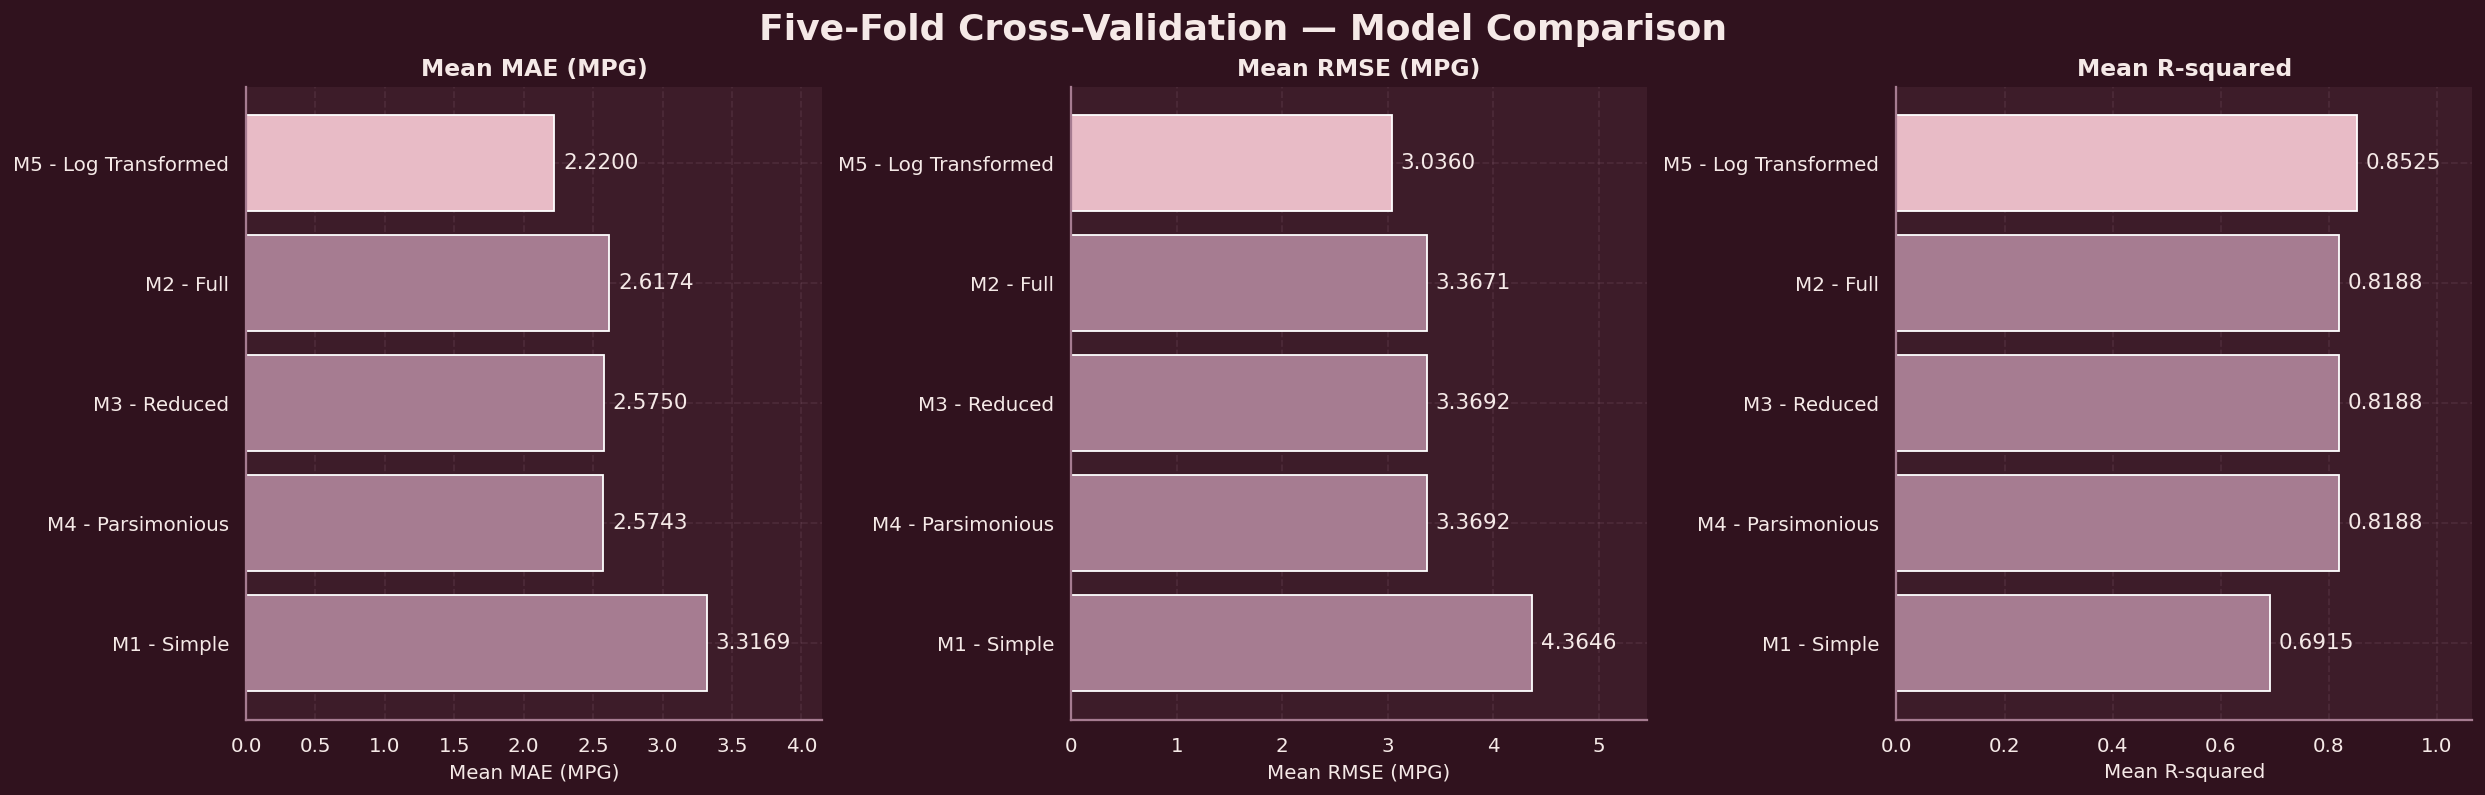

In [38]:
fig, axes = plt.subplots(
    1, 3, figsize=(19, 6),
    constrained_layout=True
)

metrics = [
    ("Mean_MAE", "Mean MAE (MPG)"),
    ("Mean_RMSE", "Mean RMSE (MPG)"),
    ("Mean_R2", "Mean R-squared")
]

for ax, (metric, label) in zip(axes, metrics):

    values = cv_summary[metric]

    best_model = (
        values.idxmax()
        if metric == "Mean_R2"
        else values.idxmin()
    )

    colors = [
        PINK if name == best_model else MAUVE
        for name in values.index
    ]

    bars = ax.barh(
        values.index,
        values,
        color=colors
    )

    ax.bar_label(
        bars, fmt="%.4f",
        padding=5, color=IVORY
    )

    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_xlim(0, values.max() * 1.25)
    ax.invert_yaxis()

fig.suptitle(
    "Five-Fold Cross-Validation — Model Comparison",
    fontsize=20,
    fontweight="bold"
)

plt.show()

### Validation Considerations

Cross-validation compares the previously specified candidate models using consistent validation folds.

Since predictor selection was performed on the complete training dataset before cross-validation, the cross-validation estimates may be optimistic.

The independent test dataset is therefore reserved for the final assessment of predictive performance.

### Interpretation of Cross-Validation Results

- Model 5 achieves the lowest mean MAE (2.2200 MPG) and RMSE (3.0360 MPG).
- Model 5 achieves the highest mean validation R-squared (0.8525).
- Model 5 demonstrates the lowest RMSE standard deviation (0.4203), indicating greater consistency across validation folds.
- The logarithmic transformation reduces RMSE by approximately 9.89% compared with Model 4.
- Models 2, 3 and 4 demonstrate nearly identical predictive performance despite differences in model complexity.
- Model 1 exhibits the weakest predictive performance.

Model 5 is provisionally preferred because it provides superior predictive accuracy while retaining a parsimonious four-predictor structure.

Final selection requires verification of its regression diagnostics and statistical inference.

In [39]:
print("MODEL 5: REGRESSION DIAGNOSTICS")
display(diagnostic_comparison.T)

print("\nMODEL 5: ROBUST STATISTICAL INFERENCE")

model5_robust = model5.get_robustcov_results(cov_type="HC3")

print(model5_robust.summary())

print("\nSENSITIVITY ANALYSIS — MODEL 4")
display(sensitivity_comparison.round(4))

MODEL 5: REGRESSION DIAGNOSTICS


,Model 4 - Original MPG,Model 5 - Log MPG
JB Statistic,4.395912e+01,6.495841
JB p-value,2.847073e-10,0.038855
BP Statistic,2.561630e+01,9.379345
BP p-value,3.781171e-05,0.052286
Residual Skewness,5.783431e-01,-0.201038
Residual Kurtosis,4.425743e+00,3.580017
Durbin-Watson,2.000908e+00,1.955260



MODEL 5: ROBUST STATISTICAL INFERENCE
                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     552.0
Date:                Wed, 25 Nov 2026   Prob (F-statistic):          4.63e-139
Time:                        11:54:36   Log-Likelihood:                 219.10
No. Observations:                 313   AIC:                            -428.2
Df Residuals:                     308   BIC:                            -409.5
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const  

,Original Coefficient,Sensitivity Coefficient,Absolute Change (%)
const,-20.4216,-15.5447,23.8811
weight,-0.0059,-0.0058,2.4128
model_year,0.7982,0.7260,9.0457
origin_europe,2.3192,1.8271,21.2221
origin_japan,2.6448,2.7743,4.8951


## 2.12 Final Model Selection and Justification

Model 5, the log-transformed multiple linear regression model with HC3 robust standard errors, is selected as the final model.

### Justification

- Highest cross-validation R-squared (0.8525).
- Lowest cross-validation RMSE (3.0360 MPG).
- Lowest cross-validation MAE (2.2200 MPG).
- Parsimonious structure containing only four predictors.
- No concerning multicollinearity.
- All retained predictors remain statistically significant under HC3 robust inference.
- Substantial improvement in residual normality.
- The Breusch-Pagan test no longer rejects homoscedasticity at the 5% significance level.

Residual normality remains imperfect, and the Breusch-Pagan p-value is close to the significance threshold. These limitations are acknowledged.

### Sensitivity Analysis

The sensitivity analysis of Model 4 shows that removing potentially influential observations changes the weight coefficient by 2.41%, model year by 9.05%, European origin by 21.22% and Japanese origin by 4.90%.

The direction of all predictor coefficients remains unchanged, although the European origin coefficient exhibits notable sensitivity.

Since these observations represent plausible automobile characteristics, they are retained. This sensitivity analysis applies to Model 4 rather than directly establishing Model 5's coefficient stability.

### Final Model Evaluation

The independent test dataset is now used to evaluate the selected model's predictive performance.

Duan's smearing correction is applied to convert logarithmic predictions back to the original MPG scale.

In [40]:
final_model = model5
final_model_robust = model5_robust
final_features = features_m4.copy()

X_test_final = sm.add_constant(
    X_test[final_features],
    has_constant="add"
)

smearing_factor = np.mean(np.exp(final_model.resid))

y_pred = (
    np.exp(final_model.predict(X_test_final))
    * smearing_factor
)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

test_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R-squared"],
    "Cross-Validation": [2.2200, 3.0360, 0.8525],
    "Independent Test": [test_mae, test_rmse, test_r2]
})

print("Final Model: Log-Transformed Multiple Regression")
print("Test observations:", len(y_test))
print(f"Smearing factor: {smearing_factor:.6f}")

display(test_results.round(4))

Final Model: Log-Transformed Multiple Regression
Test observations: 79
Smearing factor: 1.007192


,Metric,Cross-Validation,Independent Test
0,MAE,2.2200,2.0126
1,RMSE,3.0360,2.7811
2,R-squared,0.8525,0.8485


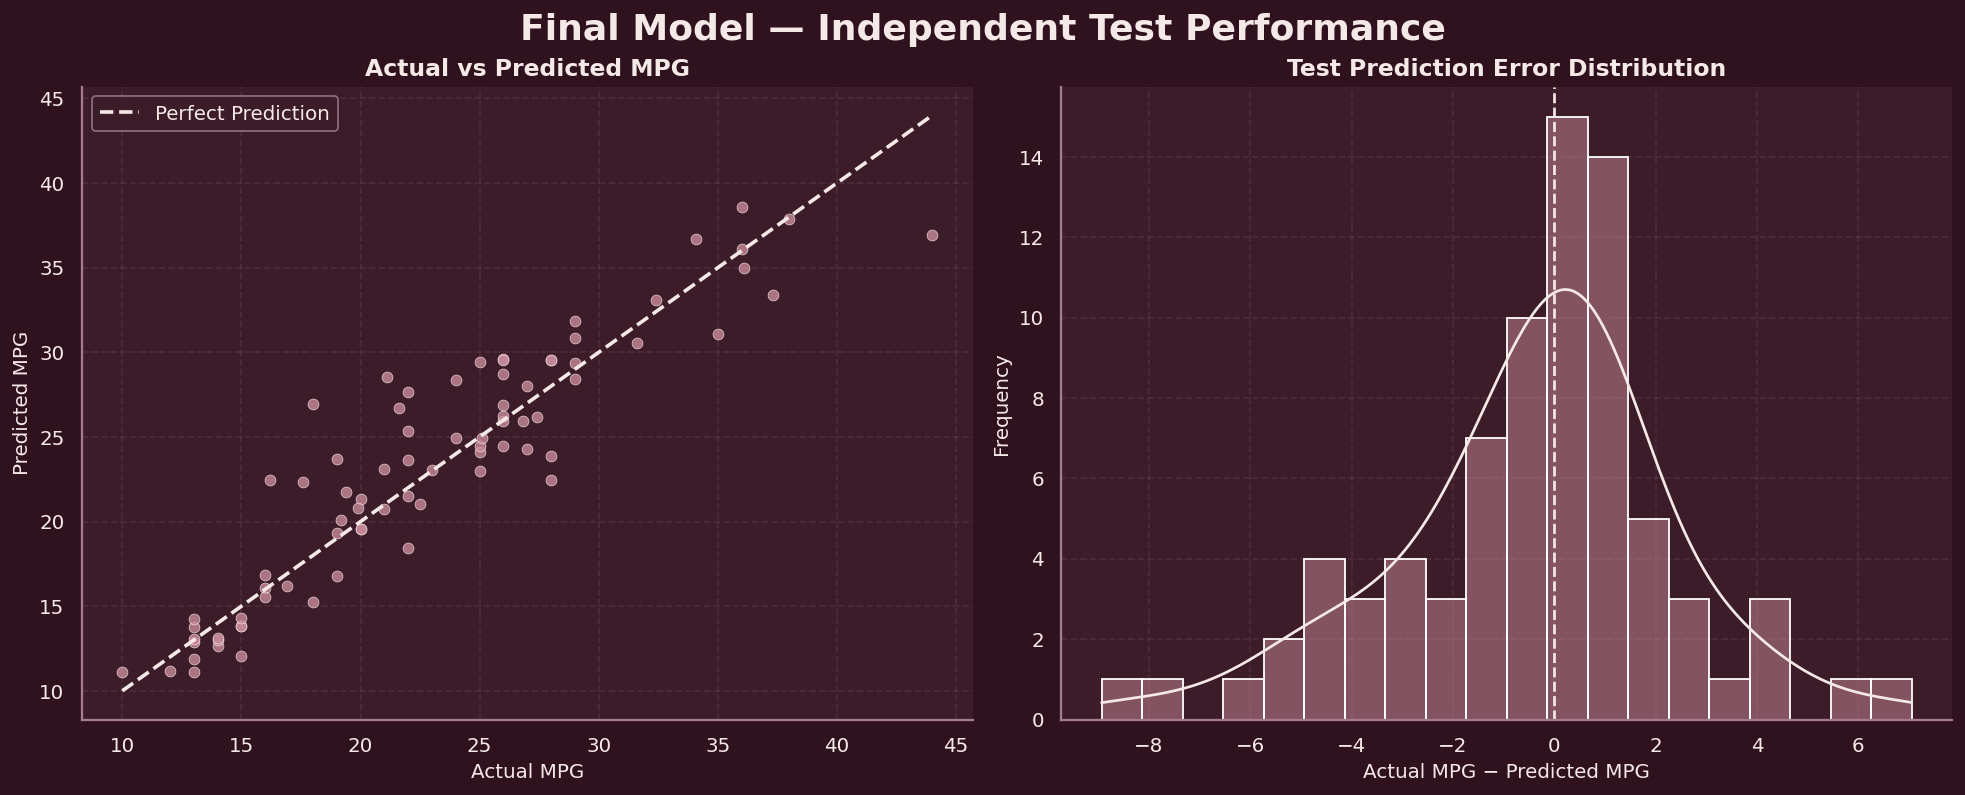

In [41]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6),
    constrained_layout=True
)

# Actual vs predicted
axes[0].scatter(
    y_test, y_pred,
    color=ROSE,
    alpha=0.8,
    edgecolor=IVORY,
    linewidth=0.4
)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

axes[0].plot(
    [lower, upper], [lower, upper],
    color=IVORY,
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

axes[0].set_title("Actual vs Predicted MPG")
axes[0].set_xlabel("Actual MPG")
axes[0].set_ylabel("Predicted MPG")
axes[0].legend()

# Test prediction errors
test_residuals = y_test - y_pred

sns.histplot(
    test_residuals,
    bins=20,
    kde=True,
    color=ROSE,
    ax=axes[1]
)

for line in axes[1].lines:
    line.set_color(IVORY)

axes[1].axvline(
    0, color=IVORY,
    linestyle="--"
)

axes[1].set_title("Test Prediction Error Distribution")
axes[1].set_xlabel("Actual MPG − Predicted MPG")
axes[1].set_ylabel("Frequency")

fig.suptitle(
    "Final Model — Independent Test Performance",
    fontsize=20,
    fontweight="bold"
)

plt.show()

In [42]:
prediction_results = pd.DataFrame({
    "Actual MPG": y_test,
    "Predicted MPG": y_pred,
    "Prediction Error": y_test - y_pred,
    "Absolute Error": np.abs(y_test - y_pred)
})

display(prediction_results.head(15).round(4))

,Actual MPG,Predicted MPG,Prediction Error,Absolute Error
78,26.0,25.9262,0.0738,0.0738
274,21.6,26.7334,-5.1334,5.1334
246,36.1,34.9563,1.1437,1.1437
55,26.0,24.4847,1.5153,1.5153
387,27.0,28.0089,-1.0089,1.0089
203,28.0,29.5454,-1.5454,1.5454
42,13.0,11.0960,1.9040,1.9040
233,26.0,29.6211,-3.6211,3.6211
150,19.0,19.3337,-0.3337,0.3337
116,29.0,29.3801,-0.3801,0.3801


### Interpretation of Independent Test Results

The final model was evaluated on 79 previously unseen observations.

- MAE of 2.0126 MPG indicates an average absolute prediction error of approximately 2 MPG.
- RMSE of 2.7811 MPG indicates relatively low prediction error, with greater emphasis on larger errors.
- Test R-squared of 0.8485 indicates that the model explains approximately 84.85% of the variation in unseen MPG observations.
- The difference between cross-validation and test R-squared is only 0.0040.
- The smearing factor of 1.007192 adjusts for back-transformation bias.

These results support the predictive accuracy and generalisation ability of the selected model.

## 2.13 Prediction and Uncertainty Estimation

Point predictions alone do not communicate the uncertainty associated with estimated fuel efficiency.

Two types of 95% intervals are constructed:

- Confidence interval: Estimates uncertainty in the conditional geometric mean MPG.
- Prediction interval: Estimates uncertainty associated with an individual vehicle's MPG.

The intervals are initially calculated on the logarithmic scale and subsequently exponentiated to obtain interpretable MPG values.

HC3 robust covariance is used to account for uncertainty in the estimated regression coefficients.

Prediction intervals remain approximate because residual normality is imperfect and the error variance may not be entirely constant.

In [43]:
prediction_summary = final_model_robust.get_prediction(
    X_test_final
).summary_frame(alpha=0.05)

prediction_summary.index = y_test.index

uncertainty_results = pd.DataFrame({
    "Actual MPG": y_test,
    "Predicted MPG": y_pred,
    "95% CI Lower": np.exp(
        prediction_summary["mean_ci_lower"]
    ),
    "95% CI Upper": np.exp(
        prediction_summary["mean_ci_upper"]
    ),
    "95% PI Lower": np.exp(
        prediction_summary["obs_ci_lower"]
    ),
    "95% PI Upper": np.exp(
        prediction_summary["obs_ci_upper"]
    )
})

display(uncertainty_results.head(15).round(4))

coverage = (
    (y_test >= uncertainty_results["95% PI Lower"]) &
    (y_test <= uncertainty_results["95% PI Upper"])
).mean() * 100

average_interval_width = (
    uncertainty_results["95% PI Upper"] -
    uncertainty_results["95% PI Lower"]
).mean()

print(f"Prediction interval coverage: {coverage:.2f}%")
print(f"Average prediction interval width: {average_interval_width:.4f} MPG")

,Actual MPG,Predicted MPG,95% CI Lower,95% CI Upper,95% PI Lower,95% PI Upper
78,26.0,25.9262,24.6787,26.8492,20.2073,32.7904
274,21.6,26.7334,25.3076,27.8377,20.8152,33.8457
246,36.1,34.9563,33.6733,35.7719,27.2942,44.1323
55,26.0,24.4847,23.3310,25.3298,19.0871,30.9616
387,27.0,28.0089,27.0392,28.6004,21.8753,35.3519
203,28.0,29.5454,28.4629,30.2326,23.0695,37.3007
42,13.0,11.0960,10.6450,11.4016,8.6591,14.0164
233,26.0,29.6211,28.5542,30.2906,23.1304,37.3933
150,19.0,19.3337,18.8836,19.5128,15.1163,24.3759
116,29.0,29.3801,27.9549,30.4386,22.8976,37.1614


Prediction interval coverage: 96.20%
Average prediction interval width: 11.2339 MPG


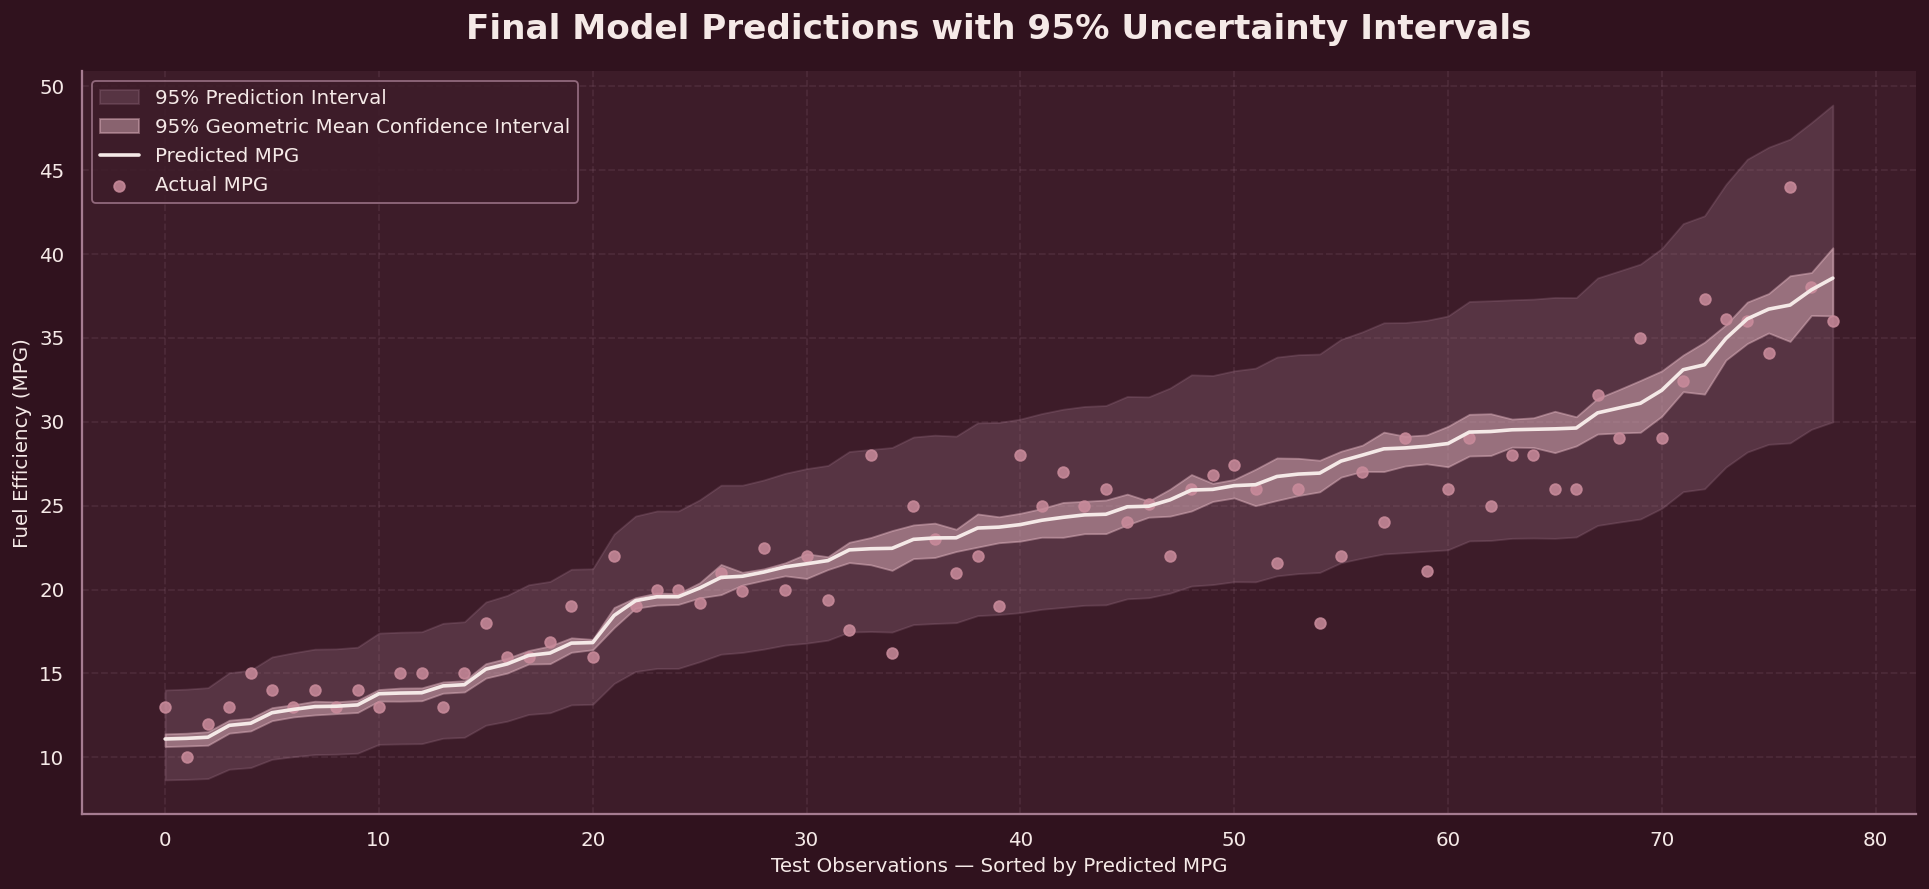

In [44]:
plot_df = uncertainty_results.sort_values(
    "Predicted MPG"
).reset_index(drop=True)

x = np.arange(len(plot_df))

plt.figure(figsize=(15, 7))

plt.fill_between(
    x,
    plot_df["95% PI Lower"],
    plot_df["95% PI Upper"],
    color=MAUVE,
    alpha=0.25,
    label="95% Prediction Interval"
)

plt.fill_between(
    x,
    plot_df["95% CI Lower"],
    plot_df["95% CI Upper"],
    color=PINK,
    alpha=0.45,
    label="95% Geometric Mean Confidence Interval"
)

plt.plot(
    x,
    plot_df["Predicted MPG"],
    color=IVORY,
    linewidth=2,
    label="Predicted MPG"
)

plt.scatter(
    x,
    plot_df["Actual MPG"],
    color=ROSE,
    s=35,
    alpha=0.85,
    label="Actual MPG"
)

plt.title(
    "Final Model Predictions with 95% Uncertainty Intervals",
    fontsize=19,
    pad=18
)

plt.xlabel("Test Observations — Sorted by Predicted MPG")
plt.ylabel("Fuel Efficiency (MPG)")
plt.legend()
plt.tight_layout()
plt.show()

## 2.14 Interpretation of Final Model Coefficients

The final model uses the natural logarithm of MPG as the dependent variable.

The percentage change associated with a change in a predictor is calculated as:

$$\text{Percentage Change} = 100(e^{\beta_j \Delta x}-1)$$

For continuous predictors:

- Weight is interpreted per 100-pound increase.
- Model year is interpreted per one-year increase.

For categorical predictors, European and Japanese vehicles are compared with American vehicles, the reference category.

All interpretations follow the ceteris paribus condition, holding other predictors constant.

The estimated effects represent statistical associations rather than causal relationships.

In [45]:
coefficients = final_model.params

robust_ci = pd.DataFrame(
    final_model_robust.conf_int(alpha=0.05),
    index=coefficients.index,
    columns=["Lower", "Upper"]
)

increments = pd.Series({
    "weight": 100,
    "model_year": 1,
    "origin_europe": 1,
    "origin_japan": 1
})

effect_table = pd.DataFrame({
    "Coefficient": coefficients[final_features],
    "Unit Change": increments,
    "Percentage Effect": 100 * np.expm1(
        coefficients[final_features] * increments
    ),
    "95% CI Lower (%)": 100 * np.expm1(
        robust_ci.loc[final_features, "Lower"] * increments
    ),
    "95% CI Upper (%)": 100 * np.expm1(
        robust_ci.loc[final_features, "Upper"] * increments
    ),
    "Robust p-value": final_model_robust.pvalues[1:]
})

display(effect_table.round(6))

,Coefficient,Unit Change,Percentage Effect,95% CI Lower (%),95% CI Upper (%),Robust p-value
weight,-0.000284,100,-2.795936,-2.990847,-2.600633,0.000000
model_year,0.033751,1,3.432692,3.011349,3.855758,0.000000
origin_europe,0.089814,1,9.397028,3.971879,15.105255,0.000585
origin_japan,0.075842,1,7.879164,3.726339,12.198253,0.000173


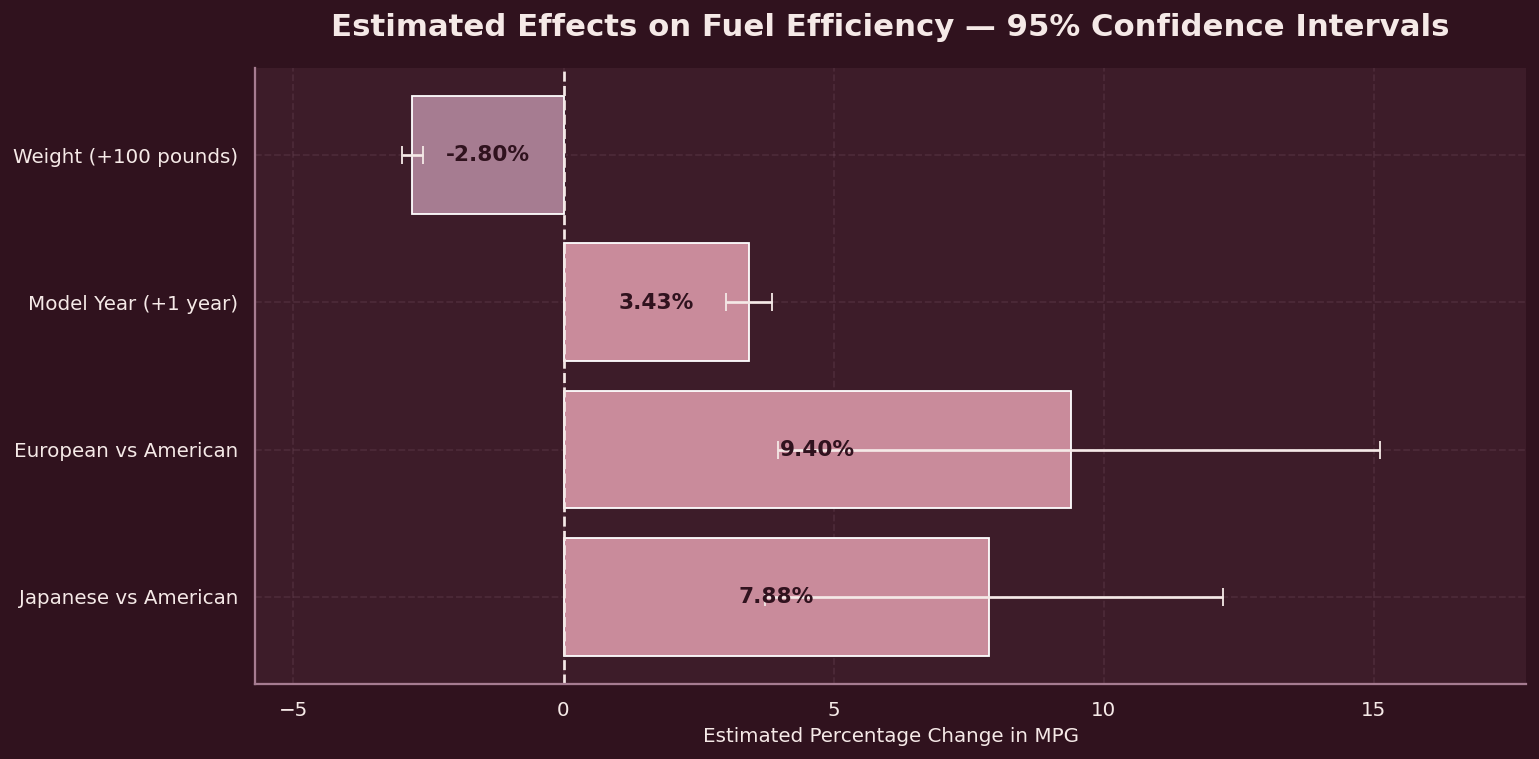

In [46]:
effects = effect_table["Percentage Effect"]

lower_error = effects - effect_table["95% CI Lower (%)"]
upper_error = effect_table["95% CI Upper (%)"] - effects

labels = [
    "Weight (+100 pounds)",
    "Model Year (+1 year)",
    "European vs American",
    "Japanese vs American"
]

plt.figure(figsize=(12, 6))

bars = plt.barh(
    labels,
    effects,
    color=[MAUVE if v < 0 else ROSE for v in effects],
    xerr=np.array([lower_error, upper_error]),
    error_kw={"ecolor": IVORY, "capsize": 5}
)

plt.axvline(0, color=IVORY, linestyle="--")

plt.bar_label(
    bars,
    fmt="%.2f%%",
    label_type="center",
    color=BURGUNDY,
    fontweight="bold"
)

plt.title(
    "Estimated Effects on Fuel Efficiency — 95% Confidence Intervals",
    fontsize=17,
    pad=18
)

plt.xlabel("Estimated Percentage Change in MPG")
plt.gca().invert_yaxis()
plt.margins(x=0.15)
plt.tight_layout()
plt.show()

### Practical Interpretation

Holding all other predictors constant:

- A 100-pound increase in vehicle weight is associated with approximately 2.8% lower geometric mean MPG.
- A one-year increase in model year is associated with approximately 3.4% higher geometric mean MPG.
- European vehicles exhibit approximately 9.4% higher geometric mean MPG than American vehicles.
- Japanese vehicles exhibit approximately 7.9% higher geometric mean MPG than American vehicles.

All four predictors are statistically significant under HC3 robust inference.

These findings highlight vehicle weight, technological progression and geographical origin as important factors associated with historical automobile fuel efficiency.

# Part 3: Interpretation, Insights and Recommendations

## 3.1 Key Findings

### Vehicle Weight and Fuel Efficiency

Vehicle weight exhibits the strongest negative marginal correlation with MPG (-0.8317). The final regression model indicates that a 100-pound increase in vehicle weight is associated with approximately 2.8% lower fuel efficiency, holding other predictors constant.

### Technological Progression

Model year demonstrates a statistically significant positive association with fuel efficiency. Each additional model year is associated with approximately 3.4% higher MPG, potentially reflecting improvements in automotive technology and engineering.

### Geographical Differences

After controlling for weight and model year, European and Japanese vehicles exhibit approximately 9.4% and 7.9% higher geometric mean MPG, respectively, compared with American vehicles.

### Predictor Redundancy

Displacement, horsepower and cylinders exhibit substantial multicollinearity. Their removal improves coefficient stability while preserving most of the model's explanatory power.

### Predictive Performance

The final log-transformed regression model achieves:

- Cross-validation R-squared: 0.8525
- Independent test R-squared: 0.8485
- Test MAE: 2.0126 MPG
- Test RMSE: 2.7811 MPG

These results demonstrate good predictive performance on previously unseen observations.

## 3.2 Actionable Recommendations

### Automobile Manufacturers

- Prioritise lightweight materials and weight-efficient vehicle designs without compromising safety or durability.
- Invest in fuel-efficient engine technologies and improved vehicle engineering.
- Investigate design and engineering practices associated with fuel-efficient European and Japanese vehicles.

### Consumers

- Consider vehicle weight and model year when evaluating historical vehicle fuel efficiency.
- Use predicted MPG as a decision-support measure rather than a guaranteed fuel consumption estimate.

### Data Analysts

- Prefer parsimonious regression models when additional predictors provide limited predictive improvement.
- Assess multicollinearity before interpreting individual regression coefficients.
- Communicate prediction uncertainty alongside point estimates.
- Perform assumption testing and independent validation before deploying regression models.

## 3.3 Limitations

### Historical Dataset

The dataset contains automobiles manufactured between 1970 and 1982. Consequently, the findings may not generalise to modern vehicles, hybrid vehicles or electric vehicles.

### Missing Observations

Six observations were removed because of missing horsepower values. Although the proportion was small, potential selection bias cannot be completely ruled out.

### Residual Assumptions

The logarithmic transformation substantially improved regression diagnostics. However, residual normality remains imperfect, and the homoscedasticity test produces a borderline result.

HC3 robust standard errors improve statistical inference but do not eliminate all model limitations.

### Omitted Variables

Important factors such as aerodynamics, transmission type, fuel type, driving conditions and maintenance history are unavailable.

### Association versus Causation

The analysis identifies statistical associations rather than causal relationships. Unobserved confounding variables may influence the estimated relationships.

### Model Selection and Validation

Predictor selection was performed before cross-validation within the training dataset, potentially introducing optimism into validation estimates.

Although an independent test dataset was used, external validation on a separate automobile dataset would provide stronger evidence of generalisability.

### Prediction Uncertainty

Prediction intervals are approximate because the underlying distributional assumptions are not perfectly satisfied.

## 3.4 Future Scope and Additional Analysis

Future investigations could improve the analysis through:

- Collection of contemporary automobile data.
- Inclusion of transmission type, aerodynamics, fuel type and engine technology.
- Investigation of nonlinear relationships and interaction effects.
- External validation using independent automobile datasets.
- Nested cross-validation to reduce model selection bias.
- Investigation of alternative regression techniques to improve predictive accuracy and uncertainty estimation.

These extensions could improve model reliability, explanatory power and practical applicability.

## 3.5 Conclusion

This study systematically investigated the factors associated with automobile fuel efficiency using exploratory data analysis, statistical inference and regression modelling.

Five regression models were developed and evaluated through statistical significance testing, multicollinearity assessment, regression diagnostics and cross-validation.

The final log-transformed multiple regression model provides the best balance of predictive accuracy, statistical reliability, interpretability and parsimony.

Using only four predictors, the model explains approximately 84.85% of the variation in MPG within the independent test dataset.

The findings highlight the importance of vehicle weight, model year and geographical origin in understanding historical fuel efficiency.

Despite certain limitations, the study demonstrates the practical value of systematic statistical modelling and inference in supporting data-driven decision-making.